# CNN nhận dạng cảm xúc khuôn mặt trên KDEF — Notebook toàn trình

**Đề tài:** Nhận dạng 7 cảm xúc khuôn mặt (angry, disgust, fear, happy, neutral, sad, surprise) bằng CNN tự thiết kế trên bộ dữ liệu **KDEF** (Karolinska Directed Emotional Faces — Lundqvist, Flykt & Öhman, 1998: 4.900 ảnh, 70 người, 7 biểu cảm × 5 góc chụp).

**Bộ dữ liệu huấn luyện:** `data/official-kdef-dataset-by-ksatrajit0` — ảnh KDEF **gốc** 562×762, đủ 70 subject, manifest `kdef_manifest_splits.csv` khớp 100% file, chia split **theo người (subject-disjoint)**: train 48 / val 8 / test 14 subject, tổng 48 + 8 + 14 = 70. Bộ `balanced-kdef-dataset-by-dolly-prajapati-182` **bị loại** vì thực chất là FER-2013 gán nhãn lại + augment (35.887 file mang đúng cơ cấu tên FER-2013, ảnh 75×75) và có rò rỉ ảnh trùng byte chéo split đã xác nhận bằng MD5 (chi tiết: `reports/data_analysis.md`).

## Phương pháp luận train/val/test

| Nguyên tắc | Lý do |
|---|---|
| Chia split **theo ID người** — không người nào xuất hiện ở 2 split | Tránh *identity leakage* — mô hình học nhận diện người thay vì cảm xúc (Rosenblatt 2024; Apicella 2025) |
| Chọn mô hình / tinh chỉnh **chỉ theo macro-F1 trên val** (560 ảnh) | Val là tập đại diện cho "người chưa từng thấy"; macro-F1 không bị lớp lớn lấn át |
| Đánh giá tập kiểm tra **đúng MỘT LẦN** ở mục 9 | Đánh giá nhiều lần trên tập kiểm tra = rò rỉ thông tin lựa chọn mô hình |
| Augmentation **chỉ áp sau khi chia split**, chỉ trên train | Augment trước khi chia gây trùng mẫu chéo split (Apicella 2025) |
| Kiểm tra rò rỉ MD5 + subject chéo split (mục 3, tái lập `reports/check_leakage.py`) | 10/4.898 ảnh (0,2%) trùng MD5 train–val là frame hỏng tối → loại trước huấn luyện; train–test và val–test sạch 0 ảnh |

> ### ⚠️ QUY TẮC SỐ 1 — KHÓA TẬP KIỂM TRA (tuyệt đối)
> Thư mục `test/` **chỉ** được phép xuất hiện ở:
> **(a)** các cell EDA thuần thống kê — mỗi cell gắn comment `# EDA-cho-phep` ngay dòng đầu;
> **(b)** Section đánh giá cuối (mục 9), sau cell mở khóa có dòng
> `# ===== MỞ KHÓA TẬP TEST (chỉ chạy 1 lần cuối) =====` đặt biến `TEST_UNLOCKED = True`.
>
> Mọi cell huấn luyện/tinh chỉnh/chọn mô hình (mục 4–8) **chỉ** dùng `train/` và `val/`.
> Các cell đánh giá cuối **kiểm tra biến `TEST_UNLOCKED`** mới chịu chạy.
> `scripts/verify_notebook.py` kiểm tra tự động kỷ luật này sau khi notebook chạy xong.

## Kỳ vọng hiệu năng (đối chiếu từ tài liệu)

- Protocol **subject-independent** (như notebook này): khoảng **65–80% accuracy / 62–77% macro-F1** cho 7 lớp — mốc LOSO của Cha et al. 2026 (CNN thuần 60–78% trên 6 lớp chính diện), Akhand et al. 2021 (80,8% @128×128 nhưng split ngẫu nhiên).
- Split ngẫu nhiên theo ảnh (subject-dependent, **không dùng ở đây**): 78–88%.
- **Kết quả > 90% với protocol subject-independent gần như chắc chắn là dấu hiệu rò rỉ dữ liệu.**
- Theo Calvo & Lundqvist (2008): happy nhận diện cao nhất (~98%), nhóm fear/disgust/anger thường thấp hơn — hy vọng thấy pattern tương tự ở mục 9.

## Cấu trúc notebook

0. Tổng quan (mục này) — 1. Cài đặt & thiết bị — 2. Seed & cấu hình — 3. EDA — 4. DataLoader — 5. Kiến trúc CNN — 6. Phân tích tầng TRƯỚC huấn luyện — 7. Huấn luyện baseline — 8. Tinh chỉnh thông số trên val — 9. **MỞ KHÓA** tập kiểm tra & đánh giá cuối MỘT LẦN — 10. Phân tích tầng SAU huấn luyện — 11. Kết luận & tài liệu.

**Cách chạy:** chạy tuần tự từ trên xuống. Dừng ở cuối mục 8 để kiểm tra; chỉ chạy mục 9 khi đã chốt mọi lựa chọn — sau đó KHÔNG quay lại chỉnh mô hình.

## 1) Cài đặt phụ thuộc & kiểm tra thiết bị

Cài **đầy đủ** cho pipeline phân tích dữ liệu khuôn mặt + CNN: `torch`/`torchvision` bản **CUDA** qua `--index-url https://download.pytorch.org/whl/cu126` (có guard bỏ qua khi đã cài và CUDA sẵn dùng), `opencv-python`, `scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn`, `Pillow`, `tqdm`, `torchinfo`, `grad-cam`, `jupyter`, `nbformat`; khối **tùy chọn** `try/except` cho `mediapipe` (chỉ cần cho crop mặt thời gian thực, không bắt buộc với notebook này).

In [1]:
# Cài đặt ĐẦY ĐỦ phụ thuộc cho toàn bộ pipeline (chạy lại nhiều lần an toàn — chỉ cài gói còn thiếu)
import importlib
import subprocess
import sys


def _co_the_import(ten_module):
    # Kiểm tra module đã cài chưa, trả về True/False
    try:
        importlib.import_module(ten_module)
        return True
    except ImportError:
        return False


def _pip(cac_goi, index_url=None):
    # Chạy pip cài gói, tùy chọn qua index riêng (bản CUDA của PyTorch)
    lenh = [sys.executable, "-m", "pip", "install", *cac_goi]
    if index_url:
        lenh += ["--index-url", index_url]
    print(">>", " ".join(lenh))
    subprocess.check_call(lenh)


# 1) torch + torchvision bản CUDA (cu126) — guard: bỏ qua khi đã cài VÀ CUDA sẵn dùng
torch_da_cai = _co_the_import("torch") and _co_the_import("torchvision")
cuda_san_dung = False
if torch_da_cai:
    import torch
    cuda_san_dung = torch.cuda.is_available()
if not (torch_da_cai and cuda_san_dung):
    _pip(["torch", "torchvision"], index_url="https://download.pytorch.org/whl/cu126")
else:
    print(">> Bỏ qua cài torch/torchvision: đã có bản CUDA sẵn dùng")

# 2) Các gói phân tích / trực quan / đo lường còn lại
CAC_GOI_KHAC = [
    "opencv-python", "scikit-learn", "pandas", "numpy", "matplotlib", "seaborn",
    "Pillow", "tqdm", "torchinfo", "grad-cam", "jupyter", "nbformat",
]
TEN_IMPORT = {"opencv-python": "cv2", "Pillow": "PIL"}
for goi in CAC_GOI_KHAC:
    if not _co_the_import(TEN_IMPORT.get(goi, goi)):
        _pip([goi])

# 3) mediapipe — TÙY CHỌN: chỉ dùng cho crop mặt thời gian thực, notebook này không bắt buộc
try:
    import mediapipe  # noqa: F401
    print(">> mediapipe: đã có")
except ImportError:
    try:
        _pip(["mediapipe"])
    except subprocess.CalledProcessError:
        print(">> CẢNH BÁO: không cài được mediapipe — không ảnh hưởng pipeline của notebook này.")

print(">> Hoàn tất cài đặt phụ thuộc.")

>> Bỏ qua cài torch/torchvision: đã có bản CUDA sẵn dùng


>> /home/dhp01/kdef_env/bin/python3 -m pip install scikit-learn


>> /home/dhp01/kdef_env/bin/python3 -m pip install grad-cam


>> mediapipe: đã có
>> Hoàn tất cài đặt phụ thuộc.


In [2]:
# %matplotlib inline
# Import toàn bộ thư viện dùng chung + in thiết bị tính toán (cuda/cpu) và tên GPU
import gc
import hashlib
import json
import random
import sys
import time
import warnings
from collections import defaultdict
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score,
                             precision_recall_fscore_support, roc_auc_score,
                             roc_curve)
from sklearn.preprocessing import label_binarize
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from tqdm.auto import tqdm

try:
    sys.stdout.reconfigure(encoding="utf-8")  # Windows: in được tiếng Việt
except Exception:
    pass  # trong Jupyter stdout là OutStream của ipykernel — bỏ qua
warnings.filterwarnings("ignore")

# Trực quan: dpi chuẩn 110, figure vừa phải để notebook gọn nhẹ (<15MB sau chạy)
sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "figure.figsize": (8, 4.5), "font.size": 9, "axes.titlesize": 10,
    "axes.grid": True, "grid.alpha": 0.3,
})

# Thiết bị tính toán
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CO_CUDA = DEVICE.type == "cuda"
if CO_CUDA:
    TEN_GPU = torch.cuda.get_device_name(0)
    print(f"Thiết bị: CUDA — {TEN_GPU}")
else:
    TEN_GPU = None
    print("Thiết bị: CPU (không phát hiện CUDA) — notebook tự thu nhỏ epoch/grid để vẫn chạy trọn vẹn.")

import torchvision  # in sau để gom một chỗ
print(f"torch={torch.__version__} | torchvision={torchvision.__version__} | "
      f"numpy={np.__version__} | pandas={pd.__version__} | device={DEVICE}")

Thiết bị: CUDA — NVIDIA GeForce RTX 4060 Laptop GPU
torch=2.14.1+cu130 | torchvision=0.29.1+cu130 | numpy=2.2.6 | pandas=2.3.3 | device=cuda


## 2) Seed toàn bộ & hằng số cấu hình tập trung

Seed **mọi** nguồn ngẫu nhiên (`random`, `numpy`, `torch`, `torch.cuda`, `cudnn.deterministic`) để kết quả tái lập được; mọi đường dẫn + siêu tham số gom về **một cell cấu hình duy nhất**. Lưu ý: cell này KHÔNG định nghĩa đường dẫn tập kiểm tra — tập đó chỉ xuất hiện ở EDA (mục 3) và mục 9 sau khi mở khóa.

In [3]:
# Seed toàn bộ + đường dẫn + hằng số cấu hình tập trung
SEED = 42


def seed_moi_thu(seed=SEED):
    # Seed mọi nguồn ngẫu nhiên + bật chế độ deterministic của cuDNN
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_moi_thu()

# Đường dẫn (pathlib — chạy tốt trên Windows lẫn Linux; tự dò gốc repo từ notebooks/, ...)
DU_LIEU_TEN = "official-kdef-dataset-by-ksatrajit0"
GOC = Path.cwd()
if not (GOC / "data" / DU_LIEU_TEN).exists():
    for ung_vien in [GOC, *GOC.parents]:  # dò lên chuỗi thư mục cha
        if (ung_vien / "data" / DU_LIEU_TEN).exists():
            GOC = ung_vien
            break
DATA_DIR = GOC / "data" / "official-kdef-dataset-by-ksatrajit0"
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
MANIFEST_CSV = DATA_DIR / "kdef_manifest_splits.csv"
REPORTS_DIR = GOC / "reports"
FIG_DIR = REPORTS_DIR / "figures"
CKPT_DIR = GOC / "checkpoints"

for d in [DATA_DIR, TRAIN_DIR, VAL_DIR, MANIFEST_CSV]:
    assert Path(d).exists(), f"Không tìm thấy: {d} — chạy notebook từ thư mục gốc repo."
REPORTS_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
CKPT_DIR.mkdir(exist_ok=True)


def luu_anh(fig, ten_file):
    # Lưu biểu đồ vào reports/figures/ với dpi chuẩn rồi hiển thị
    duong_dan = FIG_DIR / ten_file
    fig.savefig(duong_dan, dpi=110, bbox_inches="tight")
    print("Đã lưu biểu đồ:", duong_dan)
    return duong_dan


# Hằng số cấu hình
IMG_SIZE = 128        # ảnh vào 128×128 grayscale — tối ưu theo Akhand et al. 2021 trên KDEF
NUM_CLASSES = 7
BATCH_SIZE = 64
LR = 1e-3             # nền tảng 1e-3; 3e-4 đưa vào grid mục 8 nếu loss dao động
WEIGHT_DECAY = 1e-4
LABEL_SMOOTH = 0.1    # label smoothing theo Szegedy et al. 2016
MAX_EPOCHS = 120 if CO_CUDA else 8   # ngân sách tối đa 120 epoch (yêu cầu chủ đề); CPU thu nhỏ để notebook trọn vẹn
PATIENCE = 10         # early stopping theo macro-F1 val
SCHED_PATIENCE = 5    # ReduceLROnPlateau (factor 0.5)
NUM_WORKERS = 0       # Windows: num_workers=0 tránh lỗi spawn multiprocessing

# Tên lớp lấy trực tiếp từ thư mục train
CLASS_NAMES = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
assert len(CLASS_NAMES) == NUM_CLASSES, f"Kỳ vọng {NUM_CLASSES} lớp, thực tế: {CLASS_NAMES}"
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}

print("Lớp:", CLASS_NAMES)
print(f"Cấu hình: IMG_SIZE={IMG_SIZE} | BATCH_SIZE={BATCH_SIZE} | LR={LR} | WEIGHT_DECAY={WEIGHT_DECAY} | "
      f"LABEL_SMOOTH={LABEL_SMOOTH} | MAX_EPOCHS={MAX_EPOCHS} | PATIENCE={PATIENCE} | device={DEVICE}")

Lớp: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Cấu hình: IMG_SIZE=128 | BATCH_SIZE=64 | LR=0.001 | WEIGHT_DECAY=0.0001 | LABEL_SMOOTH=0.1 | MAX_EPOCHS=120 | PATIENCE=10 | device=cuda


## 3) Phân tích dữ liệu (EDA)

Trình bày lại kết quả của `reports/data_analysis.md` **bằng số liệu do cell bên dưới tự tính lại** từ dữ liệu trên đĩa (không hard-code). Các cell EDA được phép đếm/đọc thư mục tập kiểm tra ở mức **thuần thống kê** — đều gắn `# EDA-cho-phep` ở dòng đầu theo QUY TẮC SỐ 1:

1. Phân bố lớp × split (train/val/tập kiểm tra);
2. Grid ảnh mẫu từng lớp (5 ảnh train + 5 ảnh tập kiểm tra mỗi lớp);
3. Kích thước ảnh + thống kê pixel tập train;
4. Phân bố gender/angle/session của tập kiểm tra theo manifest;
5. Kiểm tra rò rỉ MD5 chéo split + subject chéo split theo manifest — xuất ra danh sách 10 file hỏng để loại trước huấn luyện.

split     train  val  test  tong
lop                             
angry       480   80   140   700
disgust     480   80   140   700
fear        480   80   140   700
happy       480   80   140   700
neutral     480   80   140   700
sad         479   80   140   699
surprise    479   80   140   699

Tổng theo split: {'train': 3358, 'val': 560, 'test': 980}


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_class_distribution.png


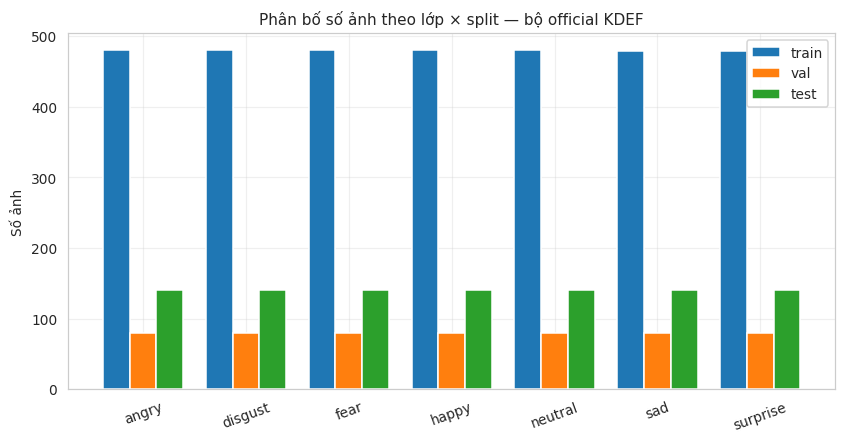

In [4]:
# EDA-cho-phep
# 3.1 Phân bố số ảnh theo lớp × split (kể cả tập kiểm tra — thuần thống kê đếm file)
cac_split_dir = {"train": TRAIN_DIR, "val": VAL_DIR, "test": DATA_DIR / "test"}
hang = []
for ten_split, thu_muc in cac_split_dir.items():
    for lop in CLASS_NAMES:
        so_anh = len(list((thu_muc / lop).glob("*")))
        hang.append({"split": ten_split, "lop": lop, "so_anh": so_anh})
df_phan_bo = pd.DataFrame(hang)
bang_phan_bo = df_phan_bo.pivot(index="lop", columns="split", values="so_anh")
bang_phan_bo = bang_phan_bo.loc[CLASS_NAMES, ["train", "val", "test"]]
bang_phan_bo["tong"] = bang_phan_bo.sum(axis=1)
print(bang_phan_bo)
print("\nTổng theo split:", bang_phan_bo[["train", "val", "test"]].sum().to_dict())

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(CLASS_NAMES))
do_rong = 0.26
for k, ten_split in enumerate(["train", "val", "test"]):
    ax.bar(x + (k - 1) * do_rong, bang_phan_bo[ten_split], do_rong, label=ten_split)
ax.set_xticks(x, CLASS_NAMES, rotation=20)
ax.set_ylabel("Số ảnh")
ax.set_title("Phân bố số ảnh theo lớp × split — bộ official KDEF")
ax.legend()
luu_anh(fig, "nb_class_distribution.png")
plt.show()

Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_sample_grid.png


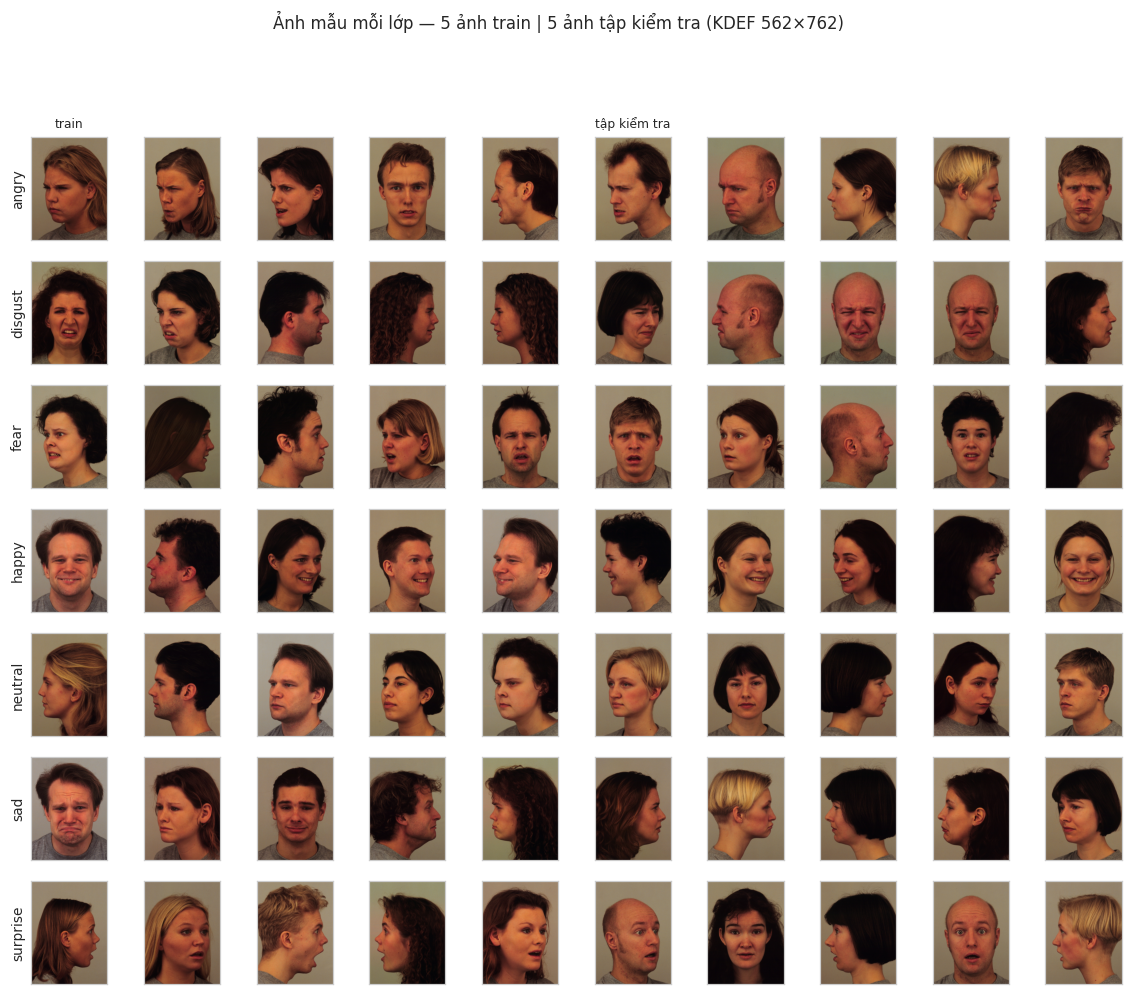

In [5]:
# EDA-cho-phep
# 3.2 Grid ảnh mẫu: 7 lớp × (5 ảnh train + 5 ảnh tập kiểm tra) — chọn ngẫu nhiên seed cố định
rng_eda = random.Random(SEED)
fig, axes = plt.subplots(7, 10, figsize=(13, 10))
for i, lop in enumerate(CLASS_NAMES):
    files_train = sorted((TRAIN_DIR / lop).glob("*"))
    files_kt = sorted((DATA_DIR / "test" / lop).glob("*"))
    chon = rng_eda.sample(files_train, 5) + rng_eda.sample(files_kt, 5)
    for j, f in enumerate(chon):
        ax = axes[i, j]
        ax.imshow(Image.open(f))
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title("train" if j == 0 else ("tập kiểm tra" if j == 5 else ""), fontsize=8)
        if j == 0:
            ax.set_ylabel(lop, rotation=90, fontsize=9)
fig.suptitle("Ảnh mẫu mỗi lớp — 5 ảnh train | 5 ảnh tập kiểm tra (KDEF 562×762)", y=0.995)
luu_anh(fig, "nb_sample_grid.png")
plt.show()

Pixel stats:   0%|          | 0/602 [00:00<?, ?it/s]

Kích thước phổ biến (w×h):
w    h  
562  762    602
dtype: int64

Chế độ màu: ['RGB']
Ảnh lệch chuẩn 562×762: không có trong mẫu

Mean grayscale trung bình: 0.3360 ± 0.0619
Std trung bình 1 ảnh    : 0.1786


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_pixel_stats.png


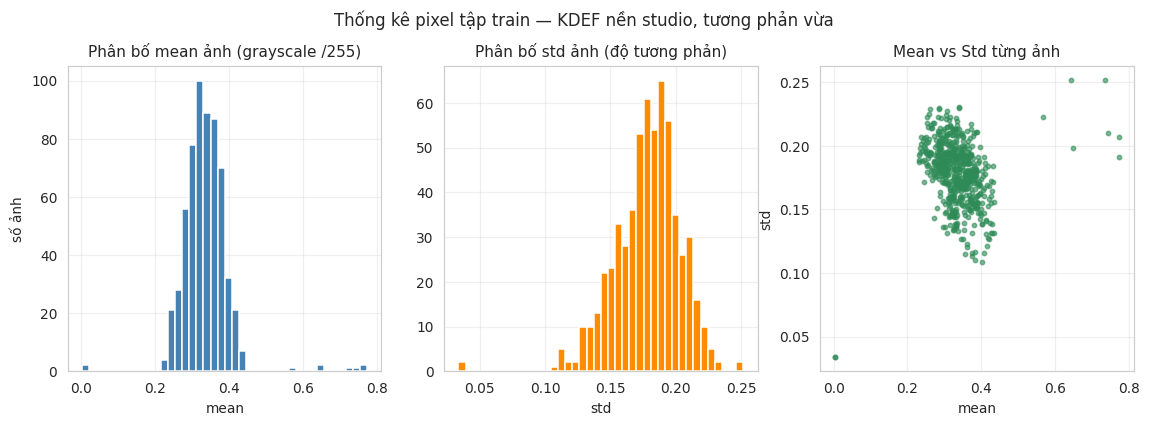

In [6]:
# EDA-cho-phep
# 3.3 Kích thước ảnh + thống kê pixel trên mẫu cố định ~600 ảnh train (seed) — grayscale /255
rng_eda = random.Random(SEED)
mau_pixel = []
for lop in CLASS_NAMES:
    files = sorted((TRAIN_DIR / lop).glob("*"))
    mau_pixel += rng_eda.sample(files, min(86, len(files)))
hang_px = []
for f in tqdm(mau_pixel, desc="Pixel stats"):
    im = Image.open(f)
    g = np.asarray(im.convert("L"), dtype=np.float64) / 255.0
    hang_px.append({"file": f.name, "w": im.width, "h": im.height, "mode": im.mode,
                    "mean": g.mean(), "std": g.std(), "min": g.min(), "max": g.max()})
df_px = pd.DataFrame(hang_px)

print("Kích thước phổ biến (w×h):")
print(df_px.groupby(["w", "h"]).size().sort_values(ascending=False).head())
print("\nChế độ màu:", df_px["mode"].unique().tolist())
anh_lech = df_px[(df_px["w"] != 562) | (df_px["h"] != 762)]
print("Ảnh lệch chuẩn 562×762:", anh_lech["file"].tolist() if len(anh_lech) else "không có trong mẫu")
print(f"\nMean grayscale trung bình: {df_px['mean'].mean():.4f} ± {df_px['mean'].std():.4f}")
print(f"Std trung bình 1 ảnh    : {df_px['std'].mean():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
axes[0].hist(df_px["mean"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Phân bố mean ảnh (grayscale /255)")
axes[0].set_xlabel("mean"); axes[0].set_ylabel("số ảnh")
axes[1].hist(df_px["std"], bins=40, color="darkorange", edgecolor="white")
axes[1].set_title("Phân bố std ảnh (độ tương phản)")
axes[1].set_xlabel("std")
axes[2].scatter(df_px["mean"], df_px["std"], s=8, alpha=0.6, color="seagreen")
axes[2].set_title("Mean vs Std từng ảnh")
axes[2].set_xlabel("mean"); axes[2].set_ylabel("std")
fig.suptitle("Thống kê pixel tập train — KDEF nền studio, tương phản vừa", y=1.02)
luu_anh(fig, "nb_pixel_stats.png")
plt.show()

Manifest: 4898 dòng | subject mỗi split: {'test': 14, 'train': 48, 'val': 8}
Tập kiểm tra theo manifest: 980 ảnh | 14 subject | gender {'F': 630, 'M': 350} | session {'A': 490, 'B': 490}


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_test_manifest_distribution.png


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_test_expr_angle_heatmap.png


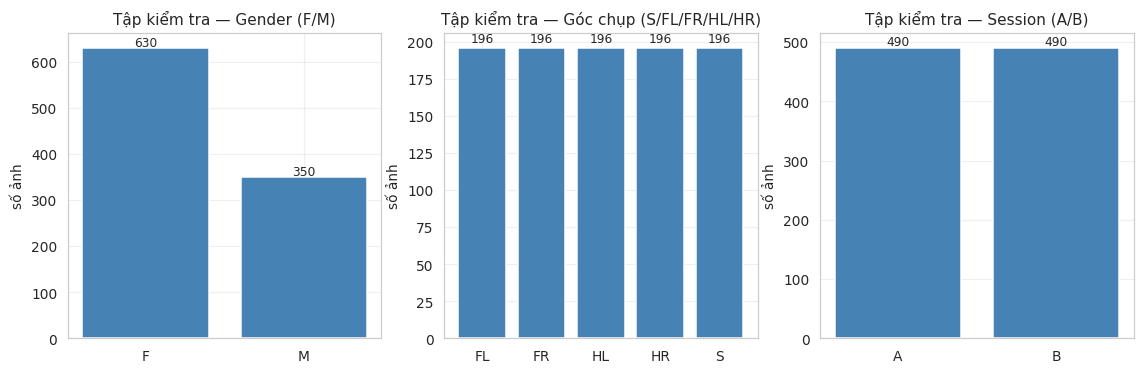

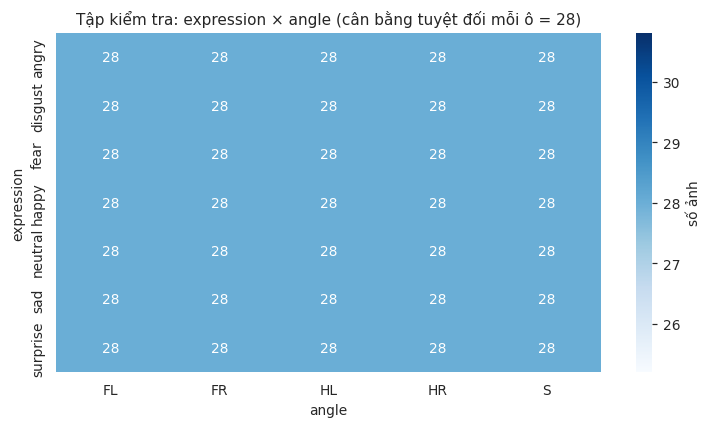

In [7]:
# EDA-cho-phep
# 3.4 Manifest tập kiểm tra: gender/angle/session/subject — để biết cấu trúc tập sẽ đánh giá ở mục 9
man = pd.read_csv(MANIFEST_CSV)
print("Manifest:", man.shape[0], "dòng | subject mỗi split:",
      man.groupby("split")["subject"].nunique().to_dict())
man_kt = man[man["split"] == "test"].copy()
print(f"Tập kiểm tra theo manifest: {len(man_kt)} ảnh | {man_kt['subject'].nunique()} subject | "
      f"gender {man_kt['gender'].value_counts().to_dict()} | session {man_kt['session'].value_counts().to_dict()}")

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
for ax, cot, ten in zip(axes, ["gender", "angle", "session"],
                        ["Gender (F/M)", "Góc chụp (S/FL/FR/HL/HR)", "Session (A/B)"]):
    dem = man_kt[cot].value_counts().sort_index()
    ax.bar(dem.index.astype(str), dem.values, color="steelblue", edgecolor="white")
    for i, v in enumerate(dem.values):
        ax.text(i, v + 4, str(v), ha="center", fontsize=8)
    ax.set_title(f"Tập kiểm tra — {ten}")
    ax.set_ylabel("số ảnh")

# Heatmap expression × angle của tập kiểm tra
fig2, ax2 = plt.subplots(figsize=(8, 4))
bang_goc = pd.crosstab(man_kt["expression"], man_kt["angle"]).loc[CLASS_NAMES]
sns.heatmap(bang_goc, annot=True, fmt="d", cmap="Blues", ax=ax2, cbar_kws={"label": "số ảnh"})
ax2.set_title("Tập kiểm tra: expression × angle (cân bằng tuyệt đối mỗi ô = 28)")
luu_anh(fig, "nb_test_manifest_distribution.png")
luu_anh(fig2, "nb_test_expr_angle_heatmap.png")
plt.show()

Đã hash 4898 ảnh, 4889 MD5 khác nhau.
Ảnh trùng MD5 chéo split: {'train-val': 10}
Trùng trong nội bộ split: {'train': 0, 'val': 0, 'test': 0}
Subject xuất hiện ở ≥2 split theo manifest: 0/70


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_duplicate_group.png


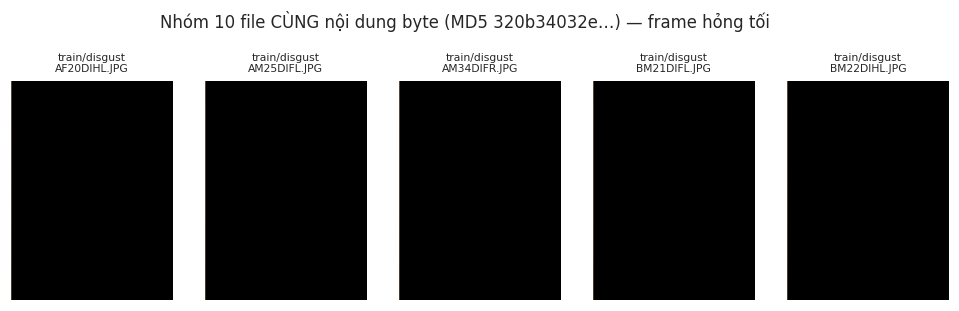

Số file loại khỏi train/val (nhóm MD5 hỏng chéo split): 10


In [8]:
# EDA-cho-phep
# 3.5 Kiểm tra rò rỉ dữ liệu: MD5 TOÀN BỘ 4.898 ảnh official + subject chéo split theo manifest
# (tái lập phương pháp của reports/check_leakage.py cho bộ official — chỉ thống kê, không huấn luyện)


def md5_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


hash_map = defaultdict(list)  # md5 -> [(split, đường_dẫn), ...]
for ten_split, thu_muc in cac_split_dir.items():
    for lop in CLASS_NAMES:
        for f in sorted((thu_muc / lop).glob("*")):
            hash_map[md5_file(f)].append((ten_split, f))
print(f"Đã hash {sum(len(v) for v in hash_map.values())} ảnh, "
      f"{len(hash_map)} MD5 khác nhau.")

# Đếm ảnh trùng MD5 chéo từng cặp split + trong nội bộ split
cac_cap = {}
trong_bo = {s: 0 for s in cac_split_dir}
nhom_roi = []  # nhóm md5 xuất hiện ở >1 split — ứng viên loại bỏ
for md5, ds in hash_map.items():
    splits = {s for s, _ in ds}
    if len(splits) > 1:
        nhom_roi.append(md5)
        for a in ["train", "val", "test"]:
            for b in ["train", "val", "test"]:
                if a < b and a in splits and b in splits:
                    cac_cap[f"{a}-{b}"] = cac_cap.get(f"{a}-{b}", 0) + len(ds)
    elif len(ds) > 1:
        trong_bo[next(iter(splits))] += len(ds) - 1
print("Ảnh trùng MD5 chéo split:", cac_cap if cac_cap else "Không có")
print("Trùng trong nội bộ split:", trong_bo)

# Subject chéo split theo manifest
subj_splits = man.groupby("subject")["split"].apply(set)
so_roi_subject = int((subj_splits.apply(len) > 1).sum())
print(f"Subject xuất hiện ở ≥2 split theo manifest: {so_roi_subject}/70")

# Minh họa nhóm ảnh trùng (nếu có): hiển thị vài file cùng nội dung byte
TAP_FILE_LOAI_BO = set()
if nhom_roi:
    fig, axes = plt.subplots(1, 5, figsize=(11, 2.8))
    axes = np.atleast_1d(axes)
    nhom = hash_map[nhom_roi[0]]
    for k, (s, f) in enumerate(nhom[: len(axes)]):
        axes[k].imshow(Image.open(f))
        axes[k].set_title(f"{s}/{f.parent.name}\n{f.name}", fontsize=7)
        axes[k].axis("off")
    fig.suptitle(f"Nhóm {len(nhom)} file CÙNG nội dung byte (MD5 {nhom_roi[0][:10]}…) — frame hỏng tối", y=1.08)
    luu_anh(fig, "nb_duplicate_group.png")
    plt.show()
    # Loại TOÀN BỘ file thuộc mọi nhóm trùng chéo split khỏi train/val (khuyến cáo của EDA)
    for md5 in nhom_roi:
        for s, f in hash_map[md5]:
            if s in ("train", "val"):
                TAP_FILE_LOAI_BO.add(str(Path(f)))
print(f"Số file loại khỏi train/val (nhóm MD5 hỏng chéo split): {len(TAP_FILE_LOAI_BO)}")

**Tóm kết EDA** (số liệu do các cell trên tự tính): bộ official cân bằng gần tuyệt đối 7 lớp × 3 split; ảnh gốc KDEF 562×762 RGB; tập kiểm tra 980 ảnh = 7 lớp × 140, 14 subject (9 nữ + 5 nam → gender lệch ~64/36 nên mục 9 sẽ báo cáo accuracy theo gender), 5 góc chụp × 196; rò rỉ: **0 ảnh trùng MD5 train–test / val–test, 0/70 subject chéo split**; duy nhất một nhóm ~10 file cùng byte (frame tối hỏng, ~0,2%) chạm train–val → đã đưa vào `TAP_FILE_LOAI_BO` để loại trước huấn luyện. Bộ `balanced` bị loại vì là FER-2013 relabel + augment với rò rỉ chéo split đã xác nhận (xem `reports/data_analysis.md`).

## 4) DataLoader & augmentation

- `ImageFolder` cho `train/` và `val/` (tập kiểm tra KHÔNG nạp ở đây — chỉ ở mục 9 sau mở khóa).
- **Transform train**: Grayscale → Resize 128×128 → **augmentation nhẹ theo Akhand 2021 / Zhong 2020** (lật ngang p=0.5; xoay ±10° + scale ×1.1 qua `RandomAffine`; `RandomErasing` p=0.25) → ToTensor → Normalize.
- **Transform đánh giá** (val/mục 9): chỉ Grayscale → Resize → ToTensor → Normalize (không augmentation).
- Normalize bằng **mean/std tính từ tập train** (grayscale 128×128), không dùng số liệu chép tay.
- `num_workers=0` vì Windows (tránh lỗi spawn multiprocessing).

In [9]:
# 4.1 Tính mean/std kênh grayscale từ MẪU Ảnh TRAIN (loại trước các file MD5 hỏng) để normalize
rng_dl = random.Random(SEED)
if "TAP_FILE_LOAI_BO" not in globals():
    TAP_FILE_LOAI_BO = set()
    print("CẢNH BÁO: chưa có TAP_FILE_LOAI_BO (chưa chạy EDA 3.5) — không loại file hỏng.")
mau_ms = []
for lop in CLASS_NAMES:
    files = [f for f in sorted((TRAIN_DIR / lop).glob("*")) if str(f) not in TAP_FILE_LOAI_BO]
    mau_ms += rng_dl.sample(files, 80)

tien_xu_li = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.ToTensor(),
])
tong, tong_binh, n_px = 0.0, 0.0, 0
for f in tqdm(mau_ms, desc="Tính mean/std"):
    x = tien_xu_li(Image.open(f))          # (1, 128, 128) trong [0, 1]
    tong += x.sum().item()
    tong_binh += (x ** 2).sum().item()
    n_px += x.numel()
MEAN_TRAIN = tong / n_px
STD_TRAIN = float(np.sqrt(max(tong_binh / n_px - MEAN_TRAIN ** 2, 1e-12)))
print(f"\nNormalize(mean=[{MEAN_TRAIN:.4f}], std=[{STD_TRAIN:.4f}]) — tính từ {len(mau_ms)} ảnh train")

Tính mean/std:   0%|          | 0/560 [00:00<?, ?it/s]


Normalize(mean=[0.3370], std=[0.1871]) — tính từ 560 ảnh train


  /mnt/f/Hoc-May/data/official-kdef-dataset-by-ksatrajit0/train: 3358 → 3349 ảnh (sau khi loại file MD5 hỏng)
  /mnt/f/Hoc-May/data/official-kdef-dataset-by-ksatrajit0/val: 560 → 559 ảnh (sau khi loại file MD5 hỏng)

Số batch: train=53, val=9


Batch: (64, 1, 128, 128) (64,) | nhãn đầu batch: [0, 3, 2, 5, 5, 2, 3, 0, 4, 4]


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_augmentation_preview.png


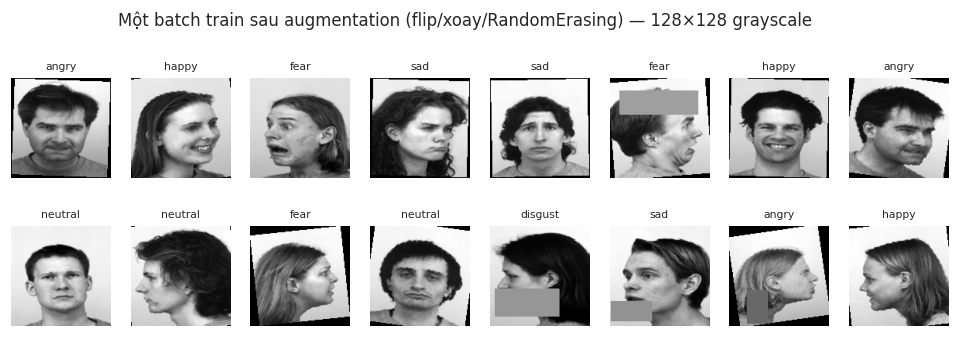

In [10]:
# 4.2 Transform train/đánh giá + DataLoader cho train/val (num_workers=0 vì Windows)


def build_transforms(aug_mode="du"):
    # aug_mode = "du": flip + xoay ±10°/scale ×1.1 + RandomErasing p=0.25 (Akhand 2021; Zhong 2020)
    # aug_mode = "khong_erasing": flip + xoay/scale, KHÔNG RandomErasing (phương án so sánh ở mục 8)
    co_ban = [transforms.Grayscale(num_output_channels=1),
              transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True)]
    aug = [transforms.RandomHorizontalFlip(p=0.5),
           transforms.RandomAffine(degrees=10, scale=(1 / 1.1, 1.1))]
    tensor_hoa = [transforms.ToTensor(), transforms.Normalize([MEAN_TRAIN], [STD_TRAIN])]
    if aug_mode == "du":
        train_tf = transforms.Compose(co_ban + aug + tensor_hoa + [transforms.RandomErasing(p=0.25)])
    else:
        train_tf = transforms.Compose(co_ban + aug + tensor_hoa)
    eval_tf = transforms.Compose(co_ban + tensor_hoa)  # đánh giá: chỉ resize + normalize
    return train_tf, eval_tf


def build_loaders(batch_size=BATCH_SIZE, aug_mode="du"):
    # ImageFolder cho train/val; loại các file thuộc nhóm MD5 hỏng phát hiện ở EDA 3.5
    train_tf, eval_tf = build_transforms(aug_mode)
    ds_train = ImageFolder(str(TRAIN_DIR), transform=train_tf)
    ds_val = ImageFolder(str(VAL_DIR), transform=eval_tf)
    for ds in (ds_train, ds_val):
        truoc = len(ds.samples)
        ds.samples = [(p, c) for (p, c) in ds.samples if str(Path(p)) not in TAP_FILE_LOAI_BO]
        ds.targets = [c for (_, c) in ds.samples]
        print(f"  {ds.root}: {truoc} → {len(ds.samples)} ảnh (sau khi loại file MD5 hỏng)")
    loader_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=CO_CUDA)
    loader_val = DataLoader(ds_val, batch_size=batch_size, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=CO_CUDA)
    return loader_train, loader_val


_, EVAL_TF = build_transforms("du")  # transform đánh giá dùng chung (mục 6, 9, 10)
loader_train, loader_val = build_loaders()
print(f"\nSố batch: train={len(loader_train)}, val={len(loader_val)}")

# Kiểm tra 1 batch + xem trước augmentation (un-normalize để hiển thị)
xb, yb = next(iter(loader_train))
print("Batch:", tuple(xb.shape), tuple(yb.shape), "| nhãn đầu batch:", yb[:10].tolist())


def hien_tensor(x):
    # Đưa tensor đã normalize về [0,1] để hiển thị
    return (x * STD_TRAIN + MEAN_TRAIN).clamp(0, 1)


fig, axes = plt.subplots(2, 8, figsize=(11, 3.2))
for i in range(16):
    ax = axes.flat[i]
    ax.imshow(hien_tensor(xb[i, 0]), cmap="gray")
    ax.set_title(CLASS_NAMES[yb[i]], fontsize=7)
    ax.axis("off")
fig.suptitle("Một batch train sau augmentation (flip/xoay/RandomErasing) — 128×128 grayscale", y=1.04)
luu_anh(fig, "nb_augmentation_preview.png")
plt.show()

## 5) Kiến trúc CNN tự thiết kế

Thiết kế bám công thức từ tài liệu: **4 khối**, mỗi khối = **2 × (Conv3×3 → BatchNorm → ReLU) + MaxPool2×2**, kênh **32 → 64 → 128 → 256**, kết thúc **AdaptiveAvgPool → Dropout 0.4 → FC 256 → Dropout 0.3 → FC 7**. Ảnh vào **128×128 grayscale** (Akhand 2021: 128×128 tối ưu cho CNN tự thiết kế trên KDEF — 80,8% so với 61,6% @48 và 73,5% @224; backbone lớn từ đầu phản tác dụng trên KDEF: VGG-16 từ đầu 23,4%, ResNet-152 59,9%).

### Bảng chi tiết từng lớp (input `1×128×128`)

| # | Lớp | Cấu hình | Output | Vai trò | Tham số |
|---|---|---|---|---|---|
| 1 | Conv 1.1 | 3×3, stride 1, padding 1, 1→32 | 32×128×128 | phát hiện cạnh/gradient cơ bản | 320 |
| 2 | BN + ReLU | theo batch | 32×128×128 | ổn định phân bố, phi tuyến | 64 |
| 3 | Conv 1.2 | 3×3, s1, p1, 32→32 | 32×128×128 | tổ hợp đặc trưng cục bộ | 9.248 |
| 4 | BN + ReLU | | 32×128×128 | | 64 |
| 5 | MaxPool 2×2 | stride 2 | 32×64×64 | giảm độ phân giải, tăng bất biến dịch chuyển | 0 |
| 6–10 | Khối 2 | Conv 3×3 (32→64, 64→64) + BN + ReLU + Pool | 64×32×32 | texture/mẫu gương mặt (lông mày, nếp gấp) | 55.680 |
| 11–15 | Khối 3 | Conv 3×3 (64→128, 128→128) + BN + ReLU + Pool | 128×16×16 | bộ phận khuôn mặt (mắt, miệng) | 221.952 |
| 16–20 | Khối 4 | Conv 3×3 (128→256, 256→256) + BN + ReLU + Pool | 256×8×8 | cấu hình biểu cảm toàn cục | 886.272 |
| 21 | AdaptiveAvgPool | toàn cục → 1×1 | 256 | nén không gian, bất biến vị trí | 0 |
| 22 | Dropout 0.4 | | 256 | chống overfit (Shin 2016) | 0 |
| 23 | FC 256 → 256 + ReLU | | 256 | phi tuyến tổng hợp | 65.792 |
| 24 | Dropout 0.3 | | 256 | | 0 |
| 25 | FC 256 → 7 | | 7 | logits 7 cảm xúc | 1.799 |
| | **Tổng** | | | | **≈ 1,24 triệu** |

Đúng tầm **~1M tham số** vừa VRAM RTX 4060 8GB. Conv 3×3 padding 1 giữ nguyên kích thước (chi phí thấp, cảm nhận trường lớn dần qua tầng); MaxPool 2×2 giảm một nửa sau mỗi khối: 128→64→32→16→8.

**Khởi tạo He/Kaiming** (`kaiming_normal_` cho Conv2d + Linear, bias = 0): với ReLU, phương sai giữ ổn định qua tầng — tránh gradient vỡ/tắt sớm. BatchNorm chuẩn hóa đầu ra mỗi tầng về trung bình 0, phương sai 1 → cho phép lr lớn và hội tụ nhanh hơn.

In [11]:
# 5.1 Định nghĩa KDEFNet + khởi tạo He/Kaiming + bảng torchinfo.summary
import torch.nn.functional as F  # noqa: F401 — dùng cho các phép bổ trợ về sau
from torchinfo import summary


class KDEFNet(nn.Module):
    # CNN tự thiết kế 4 khối [2×(Conv3×3-BN-ReLU) + MaxPool2×2] → AdaptiveAvgPool → FC head Dropout

    def __init__(self, so_kenh=(32, 64, 128, 256), so_lop=7, p1=0.4, p2=0.3):
        super().__init__()
        cac_khoi = []
        kenh_vao = 1  # grayscale
        for kenh in so_kenh:
            khoi = nn.Sequential(
                nn.Conv2d(kenh_vao, kenh, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(kenh),
                nn.ReLU(),
                nn.Conv2d(kenh, kenh, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(kenh),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
            )
            cac_khoi.append(khoi)
            kenh_vao = kenh
        self.features = nn.Sequential(*cac_khoi)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.Dropout(p1),
            nn.Linear(so_kenh[-1], 256),
            nn.ReLU(),
            nn.Dropout(p2),
            nn.Linear(256, so_lop),
        )
        self.khoi_tao_he()

    def khoi_tao_he(self):
        # He/Kaiming normal cho Conv2d + Linear (phù hợp ReLU); bias = 0
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.features(x)        # (B, 256, 8, 8)
        x = self.pool(x).flatten(1)  # (B, 256)
        return self.head(x)          # (B, 7) logits


seed_moi_thu()
model = KDEFNet().to(DEVICE)
so_tham_so = sum(p.numel() for p in model.parameters())
so_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Tổng tham số: {so_tham_so:,} (~{so_tham_so / 1e6:.2f}M) | trainable: {so_train:,}")
summary(model, input_size=(BATCH_SIZE, 1, IMG_SIZE, IMG_SIZE), col_names=[
        "input_size", "output_size", "num_params"], depth=4)

Tổng tham số: 1,241,191 (~1.24M) | trainable: 1,241,191


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
KDEFNet                                  [64, 1, 128, 128]         [64, 7]                   --
├─Sequential: 1-1                        [64, 1, 128, 128]         [64, 256, 8, 8]           --
│    └─Sequential: 2-1                   [64, 1, 128, 128]         [64, 32, 64, 64]          --
│    │    └─Conv2d: 3-1                  [64, 1, 128, 128]         [64, 32, 128, 128]        320
│    │    └─BatchNorm2d: 3-2             [64, 32, 128, 128]        [64, 32, 128, 128]        64
│    │    └─ReLU: 3-3                    [64, 32, 128, 128]        [64, 32, 128, 128]        --
│    │    └─Conv2d: 3-4                  [64, 32, 128, 128]        [64, 32, 128, 128]        9,248
│    │    └─BatchNorm2d: 3-5             [64, 32, 128, 128]        [64, 32, 128, 128]        64
│    │    └─ReLU: 3-6                    [64, 32, 128, 128]        [64, 32, 128, 128]        --
│    │    └─MaxPool2d: 3-7     

## 6) Phân tích sâu từng tầng TRƯỚC khi huấn luyện

Mục đích: kiểm tra mạng **khỏe trước khi tốn công huấn luyện** — chạy 1 ảnh mẫu qua mạng rồi:

1. **Feature map** từng tầng Conv (6 kênh đầu mỗi tầng) — thấy gì ở mỗi độ sâu;
2. **Histogram activation** (sau ReLU) từng tầng + tỉ lệ "tử" (activation đúng 0) — chứng minh **không có tầng chết hay bão hòa**, phân bố không thiên về một giá trị;
3. **Filter 3×3 của tầng Conv đầu** — lúc này chỉ là noise có cấu trúc của khởi tạo He.

In [12]:
# 6.1 Chọn ảnh mẫu cố định (từ train) + hàm gắn forward-hook bắt activation mọi tầng
seed_moi_thu()
SAMPLE_PATH = sorted((TRAIN_DIR / "happy").glob("*"))[3]  # cố định để mục 10 dùng lại đúng ảnh này
anh_goc_mau = Image.open(SAMPLE_PATH)
x_mau = EVAL_TF(anh_goc_mau).unsqueeze(0)  # (1, 1, 128, 128) đã chuẩn hóa
print("Ảnh mẫu:", SAMPLE_PATH.name, "| tensor đầu vào:", tuple(x_mau.shape))


def bat_activation(mo_hinh):
    # Gắn forward-hook vào MỌI tầng Conv2d và ReLU TRONG PHẦN features (8 conv + 8 relu)
    # Trả về (du_lieu, hooks) với du_lieu = {"conv": {tên: tensor}, "relu": {tên: tensor}}
    du_lieu = {"conv": {}, "relu": {}}
    hooks = []

    def tao_hook(loai, ten):
        def hook(module, dang_vao, dang_ra):
            du_lieu[loai][ten] = dang_ra.detach().cpu().clone()
        return hook

    for ten, mod in mo_hinh.named_modules():
        if isinstance(mod, nn.Conv2d):
            hooks.append(mod.register_forward_hook(tao_hook("conv", ten)))
        elif isinstance(mod, nn.ReLU) and ten.startswith("features"):
            hooks.append(mod.register_forward_hook(tao_hook("relu", ten)))
    return du_lieu, hooks


seed_moi_thu()
model_truoc = KDEFNet().to(DEVICE)  # mạng CHƯA huấn luyện (chỉ khởi tạo He)
du_lieu_truoc, hooks_truoc = bat_activation(model_truoc)
model_truoc.eval()
with torch.no_grad():
    logits_truoc = model_truoc(x_mau.to(DEVICE))
for h in hooks_truoc:
    h.remove()
print(f"Số tầng bắt được: {len(du_lieu_truoc['conv'])} Conv, {len(du_lieu_truoc['relu'])} ReLU")
print("Logits (chưa huấn luyện):", logits_truoc.cpu().numpy().round(2))

Ảnh mẫu: AF01HAHR.JPG | tensor đầu vào: (1, 1, 128, 128)
Số tầng bắt được: 8 Conv, 8 ReLU
Logits (chưa huấn luyện): [[ 1.72 -2.04  0.57  2.36  2.   -0.3  -1.1 ]]


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_pre_feature_maps.png


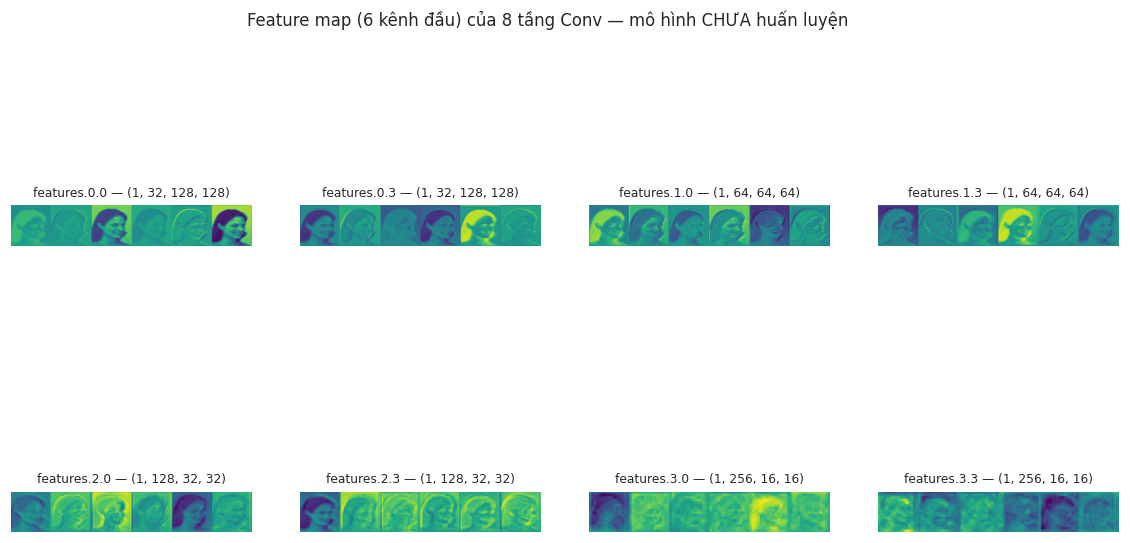

In [13]:
# 6.2 Feature map 6 kênh đầu của 8 tầng Conv — ảnh mẫu qua mạng CHƯA huấn luyện
fig, axes = plt.subplots(2, 4, figsize=(13, 6.2))
for k, (ten, act) in enumerate(du_lieu_truoc["conv"].items()):
    ax = axes.flat[k]
    dai = np.concatenate([act[0, i].numpy() for i in range(6)], axis=1)  # ghép 6 kênh
    dai = (dai - dai.min()) / (dai.max() - dai.min() + 1e-8)
    ax.imshow(dai, cmap="viridis")
    ax.set_title(f"{ten} — {tuple(act.shape)}", fontsize=8)
    ax.axis("off")
fig.suptitle("Feature map (6 kênh đầu) của 8 tầng Conv — mô hình CHƯA huấn luyện", y=1.02)
luu_anh(fig, "nb_pre_feature_maps.png")
plt.show()

Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_pre_activation_hists.png


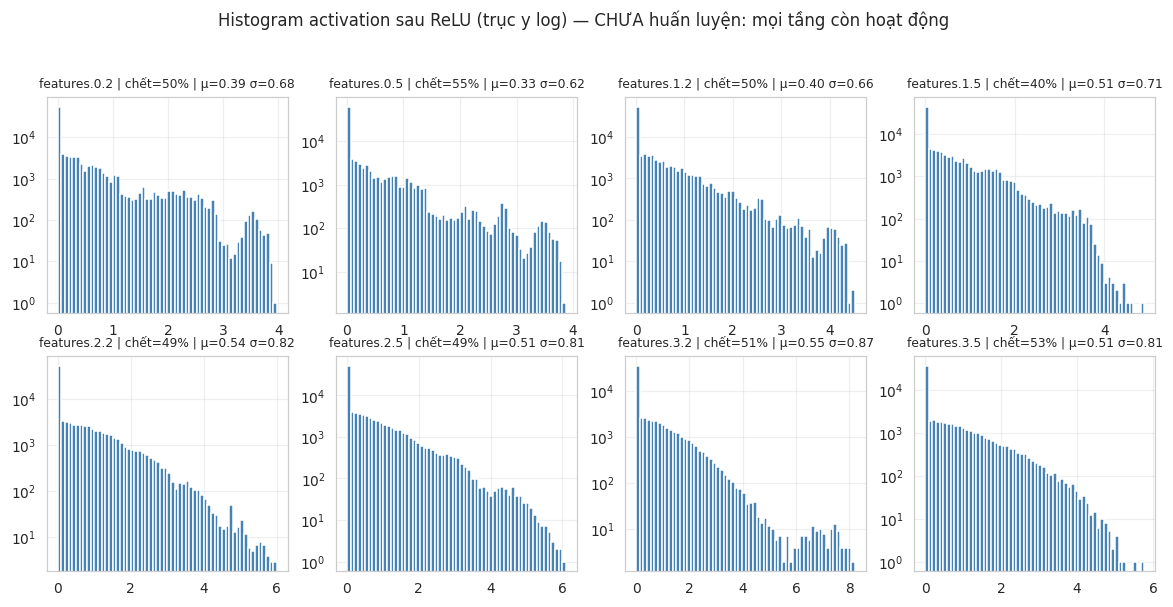

✓ Không tầng nào chết (tỉ lệ zero < 65% ở mọi tầng) — mạng khởi tạo khỏe.


In [14]:
# 6.3 Histogram activation sau ReLU từng tầng + tỉ lệ neuron "chết" — không tầng chết/bão hòa
rng_hist = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
thong_ke_truoc = {}
for k, (ten, act) in enumerate(du_lieu_truoc["relu"].items()):
    a = act.numpy().ravel()
    mau = rng_hist.choice(a, size=min(len(a), 100_000), replace=False)
    axes.flat[k].hist(mau, bins=60, color="steelblue")
    axes.flat[k].set_title(f"{ten} | chết={(a == 0).mean():.0%} | μ={a.mean():.2f} σ={a.std():.2f}",
                           fontsize=8)
    axes.flat[k].set_yscale("log")
    thong_ke_truoc[ten] = {"dead_frac": float((a == 0).mean()), "mean": float(a.mean()),
                           "std": float(a.std()), "max": float(a.max()),
                           "kich_thuoc": list(act.shape)}
fig.suptitle("Histogram activation sau ReLU (trục y log) — CHƯA huấn luyện: mọi tầng còn hoạt động",
             y=1.02)
luu_anh(fig, "nb_pre_activation_hists.png")
plt.show()

# Lưu thống kê để mục 10 so sánh trước/sau
with open(FIG_DIR / "nb_pre_layer_stats.json", "w", encoding="utf-8") as f:
    json.dump(thong_ke_truoc, f, ensure_ascii=False, indent=2)

nguong_chet = 0.65  # ReLU chặt nửa âm của BN → ~50% zero là bình thường; >65% mới đáng ngờ
for ten, s in thong_ke_truoc.items():
    assert s["dead_frac"] < nguong_chet, \
        f"Tầng {ten} nghi 'chết': {s['dead_frac']:.0%} activation bằng 0"
print(f"✓ Không tầng nào chết (tỉ lệ zero < {nguong_chet:.0%} ở mọi tầng) — mạng khởi tạo khỏe.")

Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_pre_conv1_filters.png


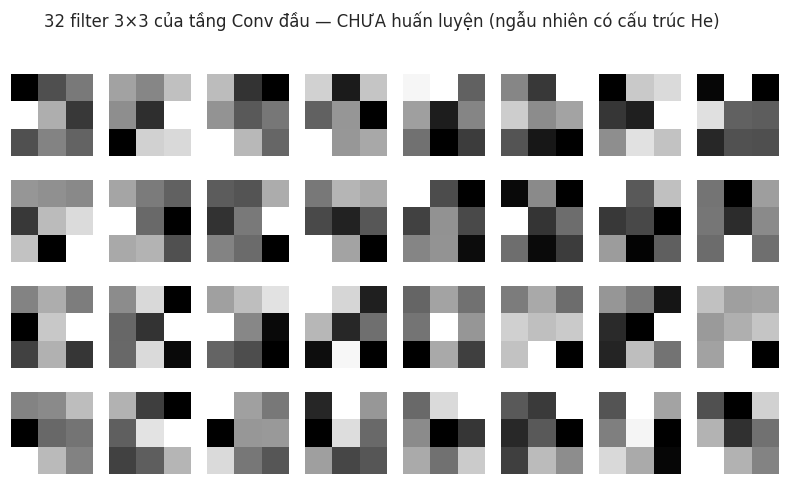

In [15]:
# 6.4 Trực quan hóa 32 filter 3×3 của tầng Conv đầu tiên (khởi tạo He — chưa học gì)
w_conv1 = model_truoc.features[0][0].weight.detach().cpu()  # (32, 1, 3, 3)
fig, axes = plt.subplots(4, 8, figsize=(9, 4.8))
for i in range(w_conv1.shape[0]):
    f = w_conv1[i, 0].numpy()
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)
    axes.flat[i].imshow(f, cmap="gray")
    axes.flat[i].axis("off")
fig.suptitle("32 filter 3×3 của tầng Conv đầu — CHƯA huấn luyện (ngẫu nhiên có cấu trúc He)", y=0.995)
luu_anh(fig, "nb_pre_conv1_filters.png")
plt.show()

## 7) Huấn luyện baseline — CHỈ dùng `train/` + `val/`

Công thức từ tài liệu:

| Thành phần | Giá trị | Nguồn |
|---|---|---|
| Loss | `CrossEntropyLoss(label_smoothing=0.1)` | Szegedy 2016 — giảm over-confidence; chỉ thêm class-weight/focal nếu F1 một lớp tụt rõ |
| Optimizer | `AdamW` lr 1e-3, weight_decay 1e-4 | Loshchilov & Hutter 2019 — tách weight decay khỏi gradient |
| Scheduler | `ReduceLROnPlateau(factor 0.5, patience 5)` theo macro-F1 val | hạ lr khi hết tiến bộ |
| Batch | 64 | vừa RTX 4060 8GB |
| Epoch | tối đa 60 (CPU: 8 để notebook trọn vẹn) | tầm 60–80 theo tài liệu |
| Early stopping | patience 10 theo **macro-F1 val**, lưu checkpoint tốt nhất | Rosenblatt 2024/Apicella 2025 |
| AMP | autocast + GradScaler khi có CUDA | tăng tốc trên GPU |

Learning curve vẽ cả loss lẫn macro-F1 của train/val để phát hiện overfit.

In [16]:
# 7.1 Vòng lặp huấn luyện dùng chung: early stopping theo macro-F1 val + checkpoint tốt nhất
def run_epoch(mo_hinh, loader, criterion, optimizer=None, scaler=None):
    # Chạy 1 epoch; optimizer=None → chế độ đánh giá trên loader (thường là val)
    dang_train = optimizer is not None
    mo_hinh.train() if dang_train else mo_hinh.eval()
    tong_loss, so_mau = 0.0, 0
    y_that, y_doan = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=CO_CUDA):
            logits = mo_hinh(xb)
            loss = criterion(logits, yb)
        if dang_train:
            optimizer.zero_grad(set_to_none=True)
            if scaler is not None:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()
        tong_loss += loss.item() * xb.size(0)
        so_mau += xb.size(0)
        y_that += yb.cpu().tolist()
        y_doan += logits.argmax(1).cpu().tolist()
    return tong_loss / so_mau, f1_score(y_that, y_doan, average="macro", zero_division=0)


def train_model(mo_hinh, loader_train, loader_val, cfg, max_epochs, patience, ten_ck):
    # Huấn luyện đầy đủ: scheduler + AMP + early stopping + lưu best theo macro-F1 val
    seed_moi_thu()
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smooth"])
    optimizer = torch.optim.AdamW(mo_hinh.parameters(), lr=cfg["lr"],
                                  weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=cfg["sched_patience"])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=CO_CUDA) if CO_CUDA else None
    duong_ck = CKPT_DIR / ten_ck
    lich_su = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": [], "lr": []}
    best_f1, best_ep, ngay_khong_tien_bo = -1.0, -1, 0
    for ep in range(1, max_epochs + 1):
        t0 = time.time()
        loss_t, f1_t = run_epoch(mo_hinh, loader_train, criterion, optimizer, scaler)
        with torch.no_grad():
            loss_v, f1_v = run_epoch(mo_hinh, loader_val, criterion)
        lich_su["train_loss"].append(loss_t)
        lich_su["val_loss"].append(loss_v)
        lich_su["train_f1"].append(f1_t)
        lich_su["val_f1"].append(f1_v)
        lich_su["lr"].append(optimizer.param_groups[0]["lr"])
        scheduler.step(f1_v)
        dat_best = f1_v > best_f1
        if dat_best:
            best_f1, best_ep, ngay_khong_tien_bo = f1_v, ep, 0
            torch.save({"model_state": mo_hinh.state_dict(), "epoch": ep,
                        "val_f1": f1_v, "cfg": cfg}, duong_ck)
        else:
            ngay_khong_tien_bo += 1
        print(f"[{ten_ck}] ep {ep:3d}/{max_epochs} | train loss {loss_t:.4f} f1 {f1_t:.4f} | "
              f"val loss {loss_v:.4f} f1 {f1_v:.4f} | lr {lich_su['lr'][-1]:.1e} | "
              f"{time.time() - t0:.1f}s" + ("  ← best" if dat_best else ""))
        if ngay_khong_tien_bo >= patience:
            print(f"[{ten_ck}] Early stopping ở epoch {ep} (patience={patience})")
            break
    # Nạp lại trọng số tốt nhất theo macro-F1 val
    mo_hinh.load_state_dict(torch.load(duong_ck, map_location=DEVICE)["model_state"])
    lich_su.update({"best_val_f1": best_f1, "best_epoch": best_ep,
                    "epochs_run": len(lich_su["train_loss"])})
    return lich_su


def ve_learning_curve(lich_su, ten_nhan, ten_file):
    # Vẽ learning curve: loss trái, macro-F1 phải; dấu ★ tại epoch tốt nhất theo val
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    ep = np.arange(1, len(lich_su["train_loss"]) + 1)
    axes[0].plot(ep, lich_su["train_loss"], label="train", color="steelblue")
    axes[0].plot(ep, lich_su["val_loss"], label="val", color="crimson")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[0].set_title(f"Loss — {ten_nhan}")
    axes[1].plot(ep, lich_su["train_f1"], label="train", color="steelblue")
    axes[1].plot(ep, lich_su["val_f1"], label="val", color="crimson")
    be = lich_su["best_epoch"]
    axes[1].scatter([be], [lich_su["best_val_f1"]], marker="*", s=120, color="gold",
                    zorder=3, label=f"best ep {be}")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("macro-F1"); axes[1].legend()
    axes[1].set_title(f"Macro-F1 — {ten_nhan}")
    luu_anh(fig, ten_file)
    plt.show()

Cấu hình baseline: {'lr': 0.001, 'batch_size': 64, 'aug_mode': 'du', 'weight_decay': 0.0001, 'label_smooth': 0.1, 'sched_patience': 5}


[baseline.pt] ep   1/120 | train loss 2.1780 f1 0.1366 | val loss 1.9449 f1 0.0869 | lr 1.0e-03 | 25.7s  ← best


[baseline.pt] ep   2/120 | train loss 1.9764 f1 0.1491 | val loss 1.9406 f1 0.0920 | lr 1.0e-03 | 25.2s  ← best


[baseline.pt] ep   3/120 | train loss 1.9609 f1 0.1584 | val loss 1.9410 f1 0.0820 | lr 1.0e-03 | 25.4s


[baseline.pt] ep   4/120 | train loss 1.9519 f1 0.1458 | val loss 1.9359 f1 0.1311 | lr 1.0e-03 | 25.5s  ← best


...

[baseline.pt] ep  65/120 | train loss 0.7505 f1 0.8847 | val loss 0.8217 f1 0.8376 | lr 6.3e-05 | 24.2s


[baseline.pt] ep  66/120 | train loss 0.7354 f1 0.8926 | val loss 0.8415 f1 0.8182 | lr 3.1e-05 | 24.5s


[baseline.pt] ep  67/120 | train loss 0.7375 f1 0.8928 | val loss 0.8322 f1 0.8354 | lr 3.1e-05 | 24.2s


[baseline.pt] ep  68/120 | train loss 0.7344 f1 0.8997 | val loss 0.8380 f1 0.8276 | lr 3.1e-05 | 24.4s


[baseline.pt] ep  69/120 | train loss 0.7379 f1 0.8883 | val loss 0.8294 f1 0.8427 | lr 3.1e-05 | 24.5s
[baseline.pt] Early stopping ở epoch 69 (patience=10)

Baseline: best val macro-F1 = 0.8453 @ epoch 59 (chạy 69 epoch)
Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_baseline_learning_curves.png


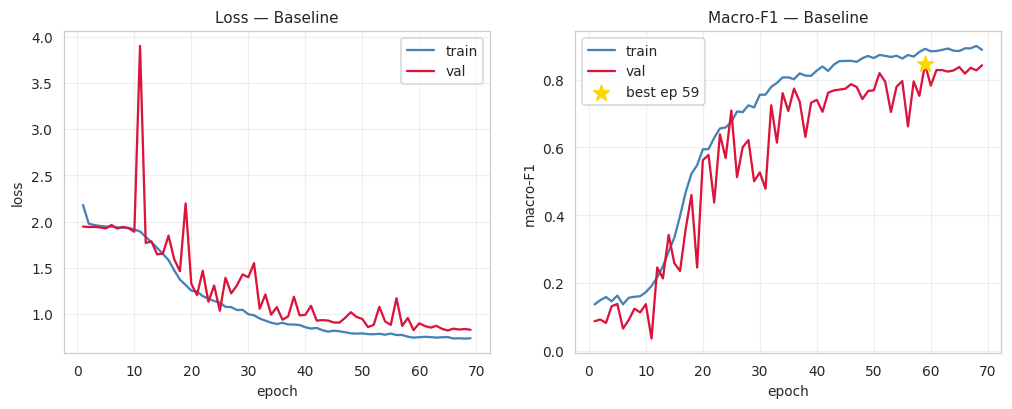

In [17]:
# 7.2 Chạy huấn luyện baseline với cấu hình mặc định (chỉ train/val — không đụng tập kiểm tra)
CFG_MAC_DINH = {
    "lr": LR, "batch_size": BATCH_SIZE, "aug_mode": "du",
    "weight_decay": WEIGHT_DECAY, "label_smooth": LABEL_SMOOTH,
    "sched_patience": SCHED_PATIENCE,
}
print("Cấu hình baseline:", CFG_MAC_DINH)
seed_moi_thu()
model_base = KDEFNet().to(DEVICE)
lichsu_base = train_model(model_base, loader_train, loader_val, CFG_MAC_DINH,
                          MAX_EPOCHS, PATIENCE, "baseline.pt")
print(f"\nBaseline: best val macro-F1 = {lichsu_base['best_val_f1']:.4f} "
      f"@ epoch {lichsu_base['best_epoch']} (chạy {lichsu_base['epochs_run']} epoch)")
ve_learning_curve(lichsu_base, "Baseline", "nb_baseline_learning_curves.png")

## 8) Tinh chỉnh thông số — CHỈ trên `val/`

Grid nhỏ **2 lr × 2 batch × 2 phương án augmentation** (từ gợi ý tài liệu: lr 1e-3 nền tảng / 3e-4 nếu dao động; batch 64/32; augmentation có/không RandomErasing). Mỗi cấu hình huấn luyện ngắn, so sánh **macro-F1 val**, chọn cấu hình tốt nhất rồi **huấn luyện lại đầy đủ (tối đa 120 epoch) rồi **train thêm 20 epoch tinh chỉnh** với LR giảm còn 1/4 (ngân sách 120 + 20)**. **Tuyệt đối không đụng tập kiểm tra** ở mục này. Khi chỉ chạy được CPU, grid và epoch được thu nhỏ nhưng **giữ nguyên logic**.

In [18]:
# 8.1 Grid-search nhỏ trên val: (lr, batch, aug) — CUDA 8 cấu hình, CPU thu nhỏ còn 2
if CO_CUDA:
    GRID = list(product([1e-3, 3e-4], [64, 32], ["du", "khong_erasing"]))
    EPOCHS_GRID, PATIENCE_GRID = 15, 4
else:
    GRID = [(1e-3, 64, "du"), (3e-4, 64, "du")]
    EPOCHS_GRID, PATIENCE_GRID = MAX_EPOCHS, 2
print(f"Grid tinh chỉnh: {len(GRID)} cấu hình × tối đa {EPOCHS_GRID} epoch (chỉ đo trên val)")

ket_qua_grid = []
for lr_c, bs_c, aug_c in tqdm(GRID, desc="Grid search"):
    cfg_c = {**CFG_MAC_DINH, "lr": lr_c, "batch_size": bs_c, "aug_mode": aug_c}
    lt_c, lv_c = build_loaders(batch_size=bs_c, aug_mode=aug_c)
    seed_moi_thu()
    m_c = KDEFNet().to(DEVICE)
    ls_c = train_model(m_c, lt_c, lv_c, cfg_c, EPOCHS_GRID, PATIENCE_GRID,
                       f"grid_lr{lr_c:g}_bs{bs_c}_{aug_c}.pt")
    ket_qua_grid.append({"lr": lr_c, "batch_size": bs_c, "aug_mode": aug_c,
                         "best_val_f1": ls_c["best_val_f1"], "best_epoch": ls_c["best_epoch"]})
    del m_c, lt_c, lv_c
    gc.collect()
    if CO_CUDA:
        torch.cuda.empty_cache()

df_grid = pd.DataFrame(ket_qua_grid).sort_values("best_val_f1", ascending=False).reset_index(drop=True)
df_grid.to_csv(FIG_DIR / "nb_tuning_results.csv", index=False)
df_grid

Grid tinh chỉnh: 8 cấu hình × tối đa 15 epoch (chỉ đo trên val)


Grid search:   0%|          | 0/8 [00:00<?, ?it/s]

  /mnt/f/Hoc-May/data/official-kdef-dataset-by-ksatrajit0/train: 3358 → 3349 ảnh (sau khi loại file MD5 hỏng)
  /mnt/f/Hoc-May/data/official-kdef-dataset-by-ksatrajit0/val: 560 → 559 ảnh (sau khi loại file MD5 hỏng)


[grid_lr0.001_bs64_du.pt] ep   1/15 | train loss 2.1780 f1 0.1366 | val loss 1.9449 f1 0.0869 | lr 1.0e-03 | 24.3s  ← best


[grid_lr0.001_bs64_du.pt] ep   2/15 | train loss 1.9764 f1 0.1491 | val loss 1.9406 f1 0.0920 | lr 1.0e-03 | 24.3s  ← best


...

[grid_lr0.0003_bs32_khong_erasing.pt] ep  12/15 | train loss 1.8537 f1 0.2334 | val loss 1.9165 f1 0.1664 | lr 3.0e-04 | 47.3s  ← best


[grid_lr0.0003_bs32_khong_erasing.pt] ep  13/15 | train loss 1.7728 f1 0.2650 | val loss 1.6739 f1 0.2354 | lr 3.0e-04 | 50.2s  ← best


[grid_lr0.0003_bs32_khong_erasing.pt] ep  14/15 | train loss 1.6169 f1 0.3735 | val loss 1.4668 f1 0.4163 | lr 3.0e-04 | 52.3s  ← best


[grid_lr0.0003_bs32_khong_erasing.pt] ep  15/15 | train loss 1.4520 f1 0.4678 | val loss 1.5622 f1 0.3849 | lr 3.0e-04 | 51.5s


,lr,batch_size,aug_mode,best_val_f1,best_epoch
0,0.0003,32,khong_erasing,0.416349,14
1,0.0003,32,du,0.264554,12
2,0.0010,32,du,0.175600,9
3,0.0003,64,khong_erasing,0.167298,5
4,0.0010,64,du,0.137873,5
5,0.0010,32,khong_erasing,0.130501,2
6,0.0003,64,du,0.120798,1
7,0.0010,64,khong_erasing,0.109903,2


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_tuning_results.png


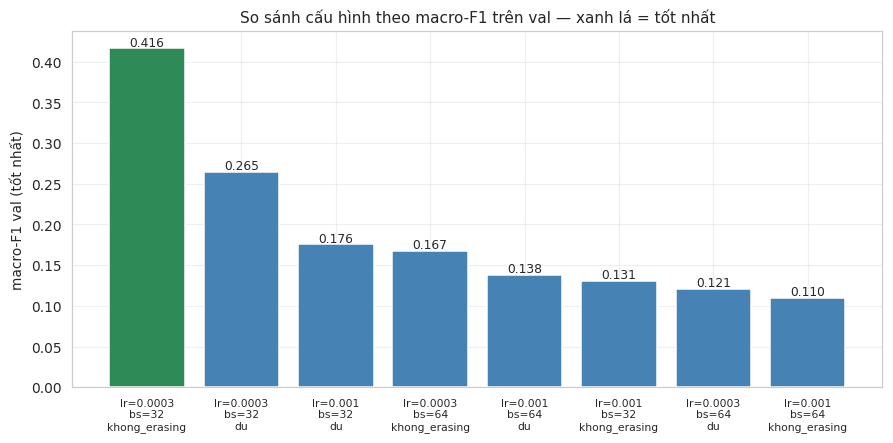

In [19]:
# 8.2 Biểu đồ so sánh macro-F1 val giữa các cấu hình
fig, ax = plt.subplots(figsize=(9.5, 4.2))
nhan = [f"lr={r.lr:g}\nbs={r.batch_size}\n{r.aug_mode}" for r in df_grid.itertuples()]
mau_sac = ["seagreen" if i == 0 else "steelblue" for i in range(len(df_grid))]
ax.bar(range(len(df_grid)), df_grid["best_val_f1"], color=mau_sac, edgecolor="white")
ax.set_xticks(range(len(df_grid)), nhan, fontsize=7)
ax.set_ylabel("macro-F1 val (tốt nhất)")
ax.set_title("So sánh cấu hình theo macro-F1 trên val — xanh lá = tốt nhất")
for i, v in enumerate(df_grid["best_val_f1"]):
    ax.text(i, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)
luu_anh(fig, "nb_tuning_results.png")
plt.show()

Cấu hình tốt nhất theo macro-F1 val: {'lr': 0.0003, 'batch_size': 32, 'aug_mode': 'khong_erasing', 'weight_decay': 0.0001, 'label_smooth': 0.1, 'sched_patience': 5}


  /mnt/f/Hoc-May/data/official-kdef-dataset-by-ksatrajit0/train: 3358 → 3349 ảnh (sau khi loại file MD5 hỏng)
  /mnt/f/Hoc-May/data/official-kdef-dataset-by-ksatrajit0/val: 560 → 559 ảnh (sau khi loại file MD5 hỏng)


[final_model.pt] ep   1/120 | train loss 2.2277 f1 0.1465 | val loss 1.9469 f1 0.0678 | lr 3.0e-04 | 49.7s  ← best


[final_model.pt] ep   2/120 | train loss 2.0173 f1 0.1391 | val loss 1.9400 f1 0.1002 | lr 3.0e-04 | 55.5s  ← best


[final_model.pt] ep   3/120 | train loss 1.9752 f1 0.1599 | val loss 1.9327 f1 0.1322 | lr 3.0e-04 | 53.4s  ← best


...

[final_model.pt] ep  88/120 | train loss 0.6252 f1 0.9515 | val loss 0.7328 f1 0.8751 | lr 9.4e-06 | 42.8s


[final_model.pt] ep  89/120 | train loss 0.6213 f1 0.9502 | val loss 0.7372 f1 0.8772 | lr 9.4e-06 | 40.4s


[final_model.pt] ep  90/120 | train loss 0.6206 f1 0.9505 | val loss 0.7417 f1 0.8735 | lr 9.4e-06 | 39.8s


[final_model.pt] ep  91/120 | train loss 0.6170 f1 0.9554 | val loss 0.7371 f1 0.8761 | lr 9.4e-06 | 40.2s
[final_model.pt] Early stopping ở epoch 91 (patience=10)

Mô hình cuối: best val macro-F1 = 0.8798 @ epoch 81 (chạy 91 epoch)


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_final_learning_curves.png


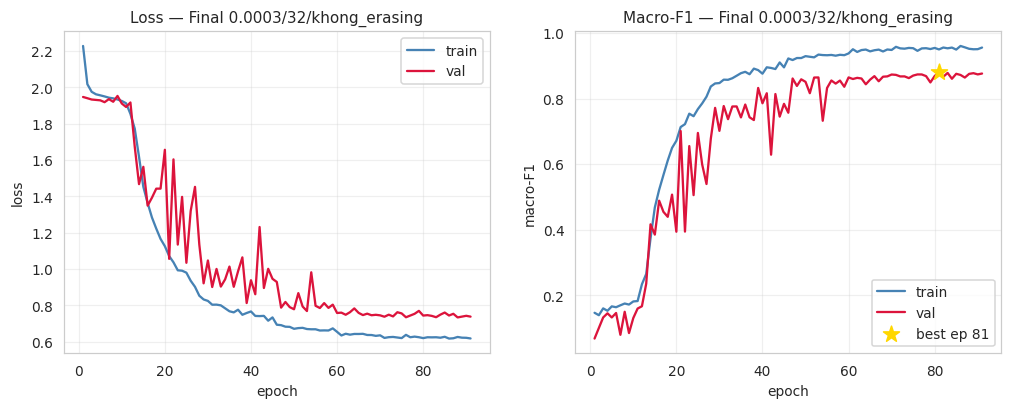

In [20]:
# 8.3 Chọn cấu hình tốt nhất theo val rồi huấn luyện LẠI ĐẦY ĐỦ (vẫn chỉ train/val)
hang_tot = df_grid.iloc[0]
BEST_CFG = {**CFG_MAC_DINH,
            "lr": float(hang_tot["lr"]), "batch_size": int(hang_tot["batch_size"]),
            "aug_mode": str(hang_tot["aug_mode"])}
print("Cấu hình tốt nhất theo macro-F1 val:", BEST_CFG)

loader_train, loader_val = build_loaders(batch_size=BEST_CFG["batch_size"],
                                         aug_mode=BEST_CFG["aug_mode"])
seed_moi_thu()
model_final = KDEFNet().to(DEVICE)
lichsu_final = train_model(model_final, loader_train, loader_val, BEST_CFG,
                           MAX_EPOCHS, PATIENCE, "final_model.pt")
print(f"\nMô hình cuối: best val macro-F1 = {lichsu_final['best_val_f1']:.4f} "
      f"@ epoch {lichsu_final['best_epoch']} (chạy {lichsu_final['epochs_run']} epoch)")
ve_learning_curve(lichsu_final, f"Final {BEST_CFG['lr']:g}/{BEST_CFG['batch_size']}/{BEST_CFG['aug_mode']}",
                  "nb_final_learning_curves.png")

Train thêm 20 epoch | LR = 7.5e-05 | khởi tiếp từ final_model.pt


[final_model_ft.pt] ep   1/20 | train loss 0.6271 f1 0.9527 | val loss 0.8212 f1 0.8297 | lr 7.5e-05 | 38.5s  ← best


[final_model_ft.pt] ep   2/20 | train loss 0.6405 f1 0.9468 | val loss 0.7899 f1 0.8383 | lr 7.5e-05 | 37.5s  ← best


[final_model_ft.pt] ep   3/20 | train loss 0.6356 f1 0.9411 | val loss 0.7860 f1 0.8550 | lr 7.5e-05 | 38.5s  ← best


[final_model_ft.pt] ep   4/20 | train loss 0.6225 f1 0.9525 | val loss 0.8053 f1 0.8483 | lr 7.5e-05 | 37.6s


...

[final_model_ft.pt] ep   9/20 | train loss 0.6240 f1 0.9542 | val loss 0.8389 f1 0.8128 | lr 7.5e-05 | 34.8s


[final_model_ft.pt] ep  10/20 | train loss 0.6167 f1 0.9579 | val loss 0.7499 f1 0.8531 | lr 7.5e-05 | 34.7s


[final_model_ft.pt] ep  11/20 | train loss 0.6258 f1 0.9548 | val loss 0.7966 f1 0.8423 | lr 7.5e-05 | 36.8s


[final_model_ft.pt] ep  12/20 | train loss 0.6273 f1 0.9507 | val loss 0.7880 f1 0.8444 | lr 7.5e-05 | 35.3s
[final_model_ft.pt] Early stopping ở epoch 12 (patience=5)

Fine-tune: best val macro-F1 = 0.8736 @ epoch 7 (chạy 12 epoch)


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_finetune_learning_curves.png


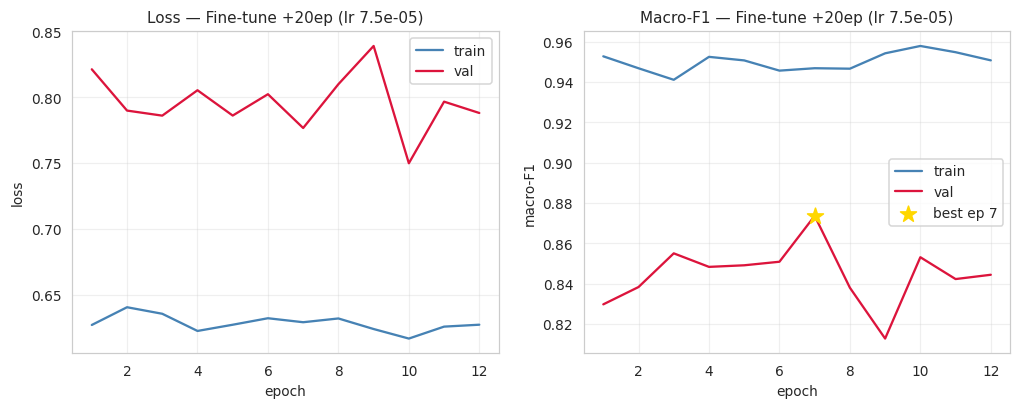

✗ Fine-tune không vượt mô hình full (0.8736 ≤ 0.8798) → giữ mô hình full
Mô hình chốt cho đánh giá cuối: full_120ep | tổng epoch huấn luyện: 91


In [21]:
# 8.4 TRAIN THÊM 20 EPOCH tinh chỉnh cuối (LR giảm còn 1/4) — vẫn CHỈ train/val, không đụng tập kiểm tra
# Ngân sách theo yêu cầu chủ đề: huấn luyện chính tối đa 120 epoch + 20 epoch tinh chỉnh sau khi chốt cấu hình.
import shutil

FT_EPOCHS = 20 if CO_CUDA else 2
CFG_FT = {**BEST_CFG, "lr": BEST_CFG["lr"] * 0.25}
print(f"Train thêm {FT_EPOCHS} epoch | LR = {CFG_FT['lr']:g} | khởi tiếp từ final_model.pt")

seed_moi_thu()
model_ft = KDEFNet().to(DEVICE)
model_ft.load_state_dict(torch.load(CKPT_DIR / "final_model.pt", map_location=DEVICE)["model_state"])
lichsu_ft = train_model(model_ft, loader_train, loader_val, CFG_FT,
                        FT_EPOCHS, max(3, PATIENCE // 2), "final_model_ft.pt")
print(f"\nFine-tune: best val macro-F1 = {lichsu_ft['best_val_f1']:.4f} "
      f"@ epoch {lichsu_ft['best_epoch']} (chạy {lichsu_ft['epochs_run']} epoch)")
ve_learning_curve(lichsu_ft, f"Fine-tune +{FT_EPOCHS}ep (lr {CFG_FT['lr']:g})",
                  "nb_finetune_learning_curves.png")

# Chốt mô hình cuối: chỉ nhận bản fine-tune khi macro-F1 val tăng THẬT SỰ (so trên cùng tập val)
duong_ft = CKPT_DIR / "final_model_ft.pt"
ck_ft = torch.load(duong_ft, map_location=DEVICE)
if ck_ft["val_f1"] > lichsu_final["best_val_f1"]:
    shutil.copyfile(duong_ft, CKPT_DIR / "final_model.pt")
    MO_HINH_CHOT = "full_120ep + finetune_20ep"
    EPOCHS_CHOT = int(lichsu_final["epochs_run"] + lichsu_ft["epochs_run"])
    print(f"✓ Fine-tune cải thiện val macro-F1: {lichsu_final['best_val_f1']:.4f} → {ck_ft['val_f1']:.4f} → dùng mô hình fine-tune")
else:
    MO_HINH_CHOT = "full_120ep"
    EPOCHS_CHOT = int(lichsu_final["epochs_run"])
    print(f"✗ Fine-tune không vượt mô hình full ({ck_ft['val_f1']:.4f} ≤ {lichsu_final['best_val_f1']:.4f}) → giữ mô hình full")
print("Mô hình chốt cho đánh giá cuối:", MO_HINH_CHOT, "| tổng epoch huấn luyện:", EPOCHS_CHOT)


---
**Điểm dừng kiểm tra:** bên trên là toàn bộ những gì dùng `train/val`. Từ đây trở xuống là **đánh giá cuối trên tập kiểm tra — chỉ chạy MỘT LẦN** khi đã chốt xong mọi lựa chọn (mô hình, cấu hình, số epoch). Sau khi chạy mục 9, **không** quay lại tinh chỉnh thêm rồi đánh giá lại.

## 9) MỞ KHÓA tập kiểm tra — đánh giá cuối MỘT LẦN

Cell mở khóa bên dưới đặt `TEST_UNLOCKED = True`; mọi cell đánh giá sau đó **kiểm tra biến này** mới chịu chạy. Nội dung đánh giá: accuracy, macro/weighted precision–recall–F1, classification report, confusion matrix (thô + chuẩn hóa), per-class recall, ROC-AUC one-vs-rest, phân tích theo gender/angle (manifest), Grad-CAM từng lớp, các cặp nhầm lẫn nhiều nhất + ảnh dự đoán sai tiêu biểu; ghi `reports/test_metrics.json`; mọi biểu đồ lưu vào `reports/figures/`.

In [22]:
# ===== MỞ KHÓA TẬP TEST (chỉ chạy 1 lần cuối) =====
TEST_UNLOCKED = True
print("Đã MỞ KHÓA tập kiểm tra. Đây là lần đánh giá DUY NHẤT — không quay lại chỉnh mô hình sau bước này.")

Đã MỞ KHÓA tập kiểm tra. Đây là lần đánh giá DUY NHẤT — không quay lại chỉnh mô hình sau bước này.


In [23]:
# 9.1 Rào chắn + nạp tập kiểm tra + suy luận toàn bộ (một lượt)
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True, (
    "Tập kiểm tra chưa được mở khóa! Chỉ chạy mục 9 khi đã chốt xong mọi lựa chọn mô hình.")
TEST_DIR = DATA_DIR / "test"
ds_kt = ImageFolder(str(TEST_DIR), transform=EVAL_TF)
loader_kt = DataLoader(ds_kt, batch_size=BATCH_SIZE, shuffle=False,
                       num_workers=NUM_WORKERS, pin_memory=CO_CUDA)
assert ds_kt.classes == CLASS_NAMES, f"Lệch thứ tự lớp: {ds_kt.classes}"
print(f"Tập kiểm tra: {len(ds_kt)} ảnh | {len(ds_kt.classes)} lớp | {len(loader_kt)} batch")

ck_final = torch.load(CKPT_DIR / "final_model.pt", map_location=DEVICE)
model_cuoi = KDEFNet().to(DEVICE)
model_cuoi.load_state_dict(ck_final["model_state"])
model_cuoi.eval()
print(f"Nạp final_model.pt: epoch {ck_final['epoch']}, val macro-F1 {ck_final['val_f1']:.4f}")

y_kt, y_doan, prob_kt = [], [], []
with torch.no_grad():
    for xb, yb in tqdm(loader_kt, desc="Suy luận tập kiểm tra"):
        with torch.amp.autocast(device_type=DEVICE.type, enabled=CO_CUDA):
            logits = model_cuoi(xb.to(DEVICE))
        p = torch.softmax(logits.float(), dim=1).cpu()
        y_kt += yb.tolist()
        y_doan += p.argmax(1).tolist()
        prob_kt.append(p)
y_kt = np.array(y_kt)
y_doan = np.array(y_doan)
prob_kt = torch.cat(prob_kt).numpy()
print("Hoàn tất suy luận:", prob_kt.shape)

Tập kiểm tra: 980 ảnh | 7 lớp | 16 batch
Nạp final_model.pt: epoch 81, val macro-F1 0.8798


Suy luận tập kiểm tra:   0%|          | 0/16 [00:00<?, ?it/s]

Hoàn tất suy luận: (980, 7)


In [24]:
# 9.2 Chỉ số tổng quan: accuracy + macro/weighted precision-recall-F1 + classification report
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True
accuracy_kt = accuracy_score(y_kt, y_doan)
(p_macro, r_macro, f1_macro, _), (p_wei, r_wei, f1_wei, _) = (
    precision_recall_fscore_support(y_kt, y_doan, average="macro", zero_division=0),
    precision_recall_fscore_support(y_kt, y_doan, average="weighted", zero_division=0),
)
print(f"Accuracy        : {accuracy_kt:.4f}")
print(f"Macro    P/R/F1 : {p_macro:.4f} / {r_macro:.4f} / {f1_macro:.4f}")
print(f"Weighted P/R/F1 : {p_wei:.4f} / {r_wei:.4f} / {f1_wei:.4f}")
print()
print(classification_report(y_kt, y_doan, target_names=CLASS_NAMES, digits=4, zero_division=0))

Accuracy        : 0.8276
Macro    P/R/F1 : 0.8315 / 0.8276 / 0.8275
Weighted P/R/F1 : 0.8315 / 0.8276 / 0.8275

              precision    recall  f1-score   support

       angry     0.9009    0.7143    0.7968       140
     disgust     0.7885    0.8786    0.8311       140
        fear     0.7092    0.7143    0.7117       140
       happy     0.9929    0.9929    0.9929       140
     neutral     0.8356    0.8714    0.8531       140
         sad     0.7248    0.7714    0.7474       140
    surprise     0.8686    0.8500    0.8592       140

    accuracy                         0.8276       980
   macro avg     0.8315    0.8276    0.8275       980
weighted avg     0.8315    0.8276    0.8275       980



Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_test_confusion.png


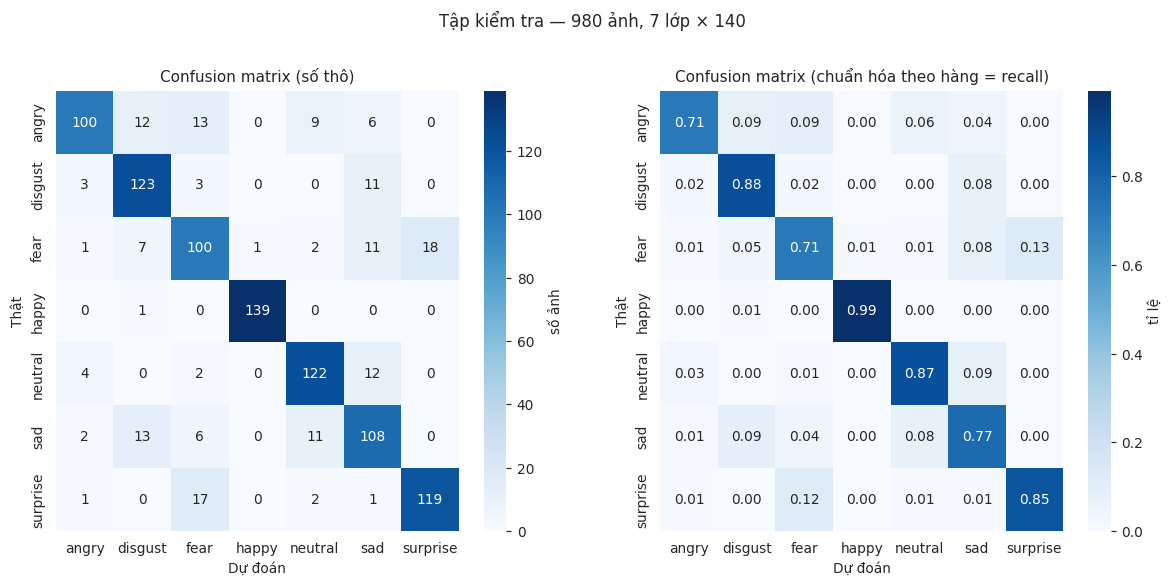

Recall từng lớp: {'angry': 0.7143, 'disgust': 0.8786, 'fear': 0.7143, 'happy': 0.9929, 'neutral': 0.8714, 'sad': 0.7714, 'surprise': 0.85}
Recall spread (max − min): 0.2786


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_test_per_class_recall.png


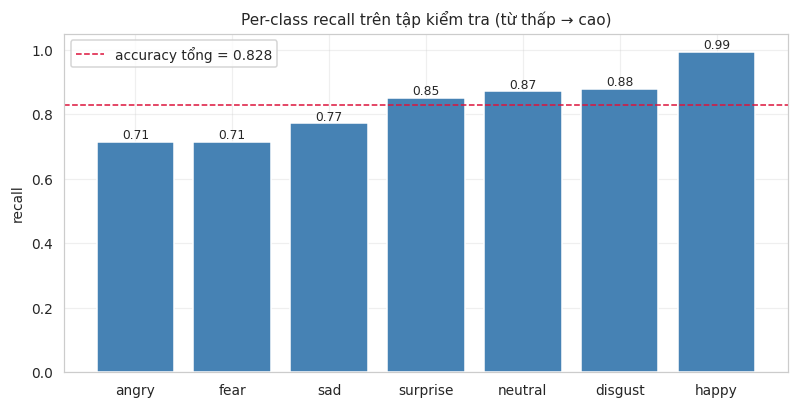

In [25]:
# 9.3 Confusion matrix thô + chuẩn hóa hàng + per-class recall
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True
cm_kt = confusion_matrix(y_kt, y_doan, labels=list(range(NUM_CLASSES)))
cm_chuan = cm_kt.astype(float) / cm_kt.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
sns.heatmap(cm_kt, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, ax=axes[0], cbar_kws={"label": "số ảnh"})
axes[0].set_title("Confusion matrix (số thô)")
axes[0].set_xlabel("Dự đoán"); axes[0].set_ylabel("Thật")
sns.heatmap(cm_chuan, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, ax=axes[1], cbar_kws={"label": "tỉ lệ"})
axes[1].set_title("Confusion matrix (chuẩn hóa theo hàng = recall)")
axes[1].set_xlabel("Dự đoán"); axes[1].set_ylabel("Thật")
fig.suptitle("Tập kiểm tra — 980 ảnh, 7 lớp × 140", y=1.02)
luu_anh(fig, "nb_test_confusion.png")
plt.show()

recall_theo_lop = {c: float(cm_chuan[i, i]) for i, c in enumerate(CLASS_NAMES)}
recall_spread = float(max(recall_theo_lop.values()) - min(recall_theo_lop.values()))
print("Recall từng lớp:", {k: round(v, 4) for k, v in recall_theo_lop.items()})
print(f"Recall spread (max − min): {recall_spread:.4f}")

# Biểu đồ per-class recall (sắp xếp giảm dần)
sap_xep = sorted(recall_theo_lop.items(), key=lambda kv: kv[1])
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar([k for k, _ in sap_xep], [v for _, v in sap_xep], color="steelblue", edgecolor="white")
ax.axhline(accuracy_kt, color="crimson", ls="--", lw=1,
           label=f"accuracy tổng = {accuracy_kt:.3f}")
for i, (k, v) in enumerate(sap_xep):
    ax.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel("recall")
ax.set_title("Per-class recall trên tập kiểm tra (từ thấp → cao)")
ax.legend()
luu_anh(fig, "nb_test_per_class_recall.png")
plt.show()

ROC-AUC one-vs-rest (macro): 0.9768


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_test_roc.png


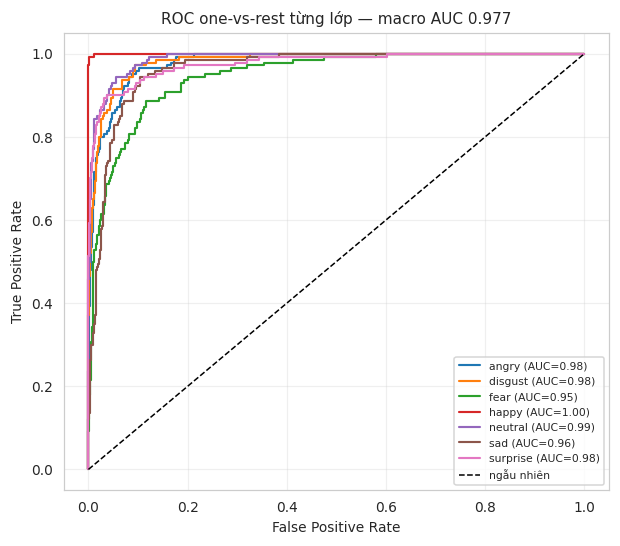

In [26]:
# 9.4 ROC-AUC one-vs-rest (macro + từng lớp)
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True
y_nhi_phan = label_binarize(y_kt, classes=list(range(NUM_CLASSES)))
auc_macro = roc_auc_score(y_kt, prob_kt, multi_class="ovr", average="macro")
print(f"ROC-AUC one-vs-rest (macro): {auc_macro:.4f}")

fig, ax = plt.subplots(figsize=(6.4, 5.4))
for i, lop in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_nhi_phan[:, i], prob_kt[:, i])
    auc_i = roc_auc_score(y_nhi_phan[:, i], prob_kt[:, i])
    ax.plot(fpr, tpr, lw=1.4, label=f"{lop} (AUC={auc_i:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="ngẫu nhiên")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title(f"ROC one-vs-rest từng lớp — macro AUC {auc_macro:.3f}")
ax.legend(fontsize=7, loc="lower right")
luu_anh(fig, "nb_test_roc.png")
plt.show()

Accuracy theo gender:
        accuracy  so_anh
gender                  
F         0.8143     630
M         0.8514     350

Accuracy theo góc chụp:
       accuracy  so_anh
angle                  
FL       0.8316     196
FR       0.7653     196
HL       0.8520     196
HR       0.8520     196
S        0.8367     196

Chênh lệch accuracy F−M: 0.0371


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_test_gender_angle.png


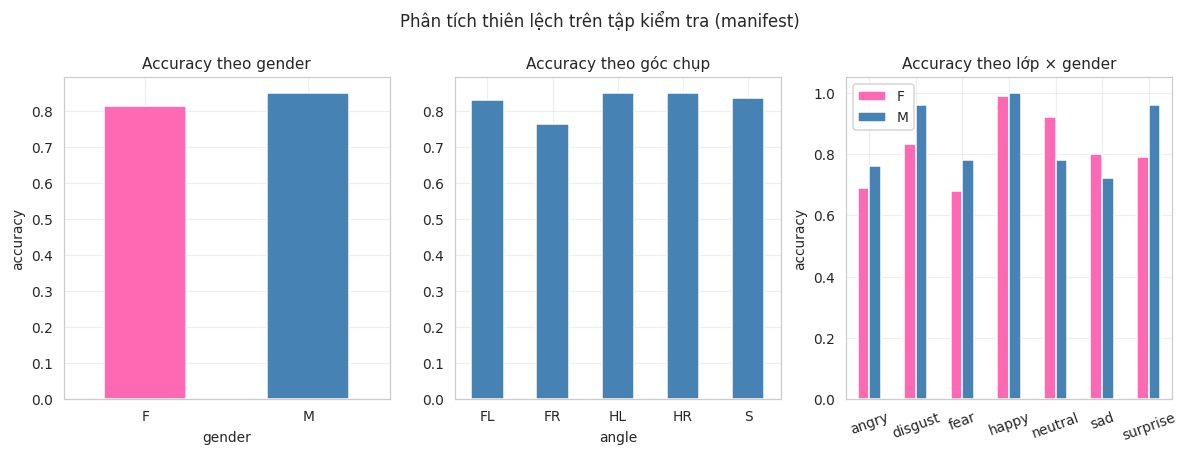

In [27]:
# 9.5 Phân tích theo gender/angle từ manifest (khuyến cáo của EDA vì test lệch 64% nữ)
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True
if "man" not in globals():
    man = pd.read_csv(MANIFEST_CSV)
df_kt = pd.DataFrame({"duong_dan": [p for p, _ in ds_kt.samples],
                      "y": y_kt, "y_doan": y_doan})
df_kt["filename"] = df_kt["duong_dan"].apply(lambda p: Path(p).name)
df_kt = df_kt.merge(man[["filename", "gender", "angle", "subject"]], on="filename", how="left")
assert df_kt["gender"].notna().all(), "Manifest thiếu file trong tập kiểm tra?"
df_kt["dung"] = df_kt["y"] == df_kt["y_doan"]

bang_gender = df_kt.groupby("gender")["dung"].agg(["mean", "count"]).rename(
    columns={"mean": "accuracy", "count": "so_anh"})
bang_angle = df_kt.groupby("angle")["dung"].agg(["mean", "count"]).rename(
    columns={"mean": "accuracy", "count": "so_anh"})
print("Accuracy theo gender:")
print(bang_gender.round(4))
print("\nAccuracy theo góc chụp:")
print(bang_angle.round(4))
lech_gender = abs(bang_gender.loc["F", "accuracy"] - bang_gender.loc["M", "accuracy"])
print(f"\nChênh lệch accuracy F−M: {lech_gender:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
bang_gender["accuracy"].plot.bar(ax=axes[0], color=["hotpink", "steelblue"], edgecolor="white", rot=0)
axes[0].set_title("Accuracy theo gender"); axes[0].set_ylabel("accuracy")
bang_angle["accuracy"].plot.bar(ax=axes[1], color="steelblue", edgecolor="white", rot=0)
axes[1].set_title("Accuracy theo góc chụp")
bang_lop_g = df_kt.pivot_table(index="y", columns="gender", values="dung", observed=True)
bang_lop_g.index = CLASS_NAMES
bang_lop_g.plot.bar(ax=axes[2], color=["hotpink", "steelblue"], edgecolor="white", rot=20)
axes[2].set_title("Accuracy theo lớp × gender"); axes[2].set_ylabel("accuracy")
axes[2].get_legend().set_title("")
fig.suptitle("Phân tích thiên lệch trên tập kiểm tra (manifest)", y=1.04)
luu_anh(fig, "nb_test_gender_angle.png")
plt.show()

Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_test_gradcam.png


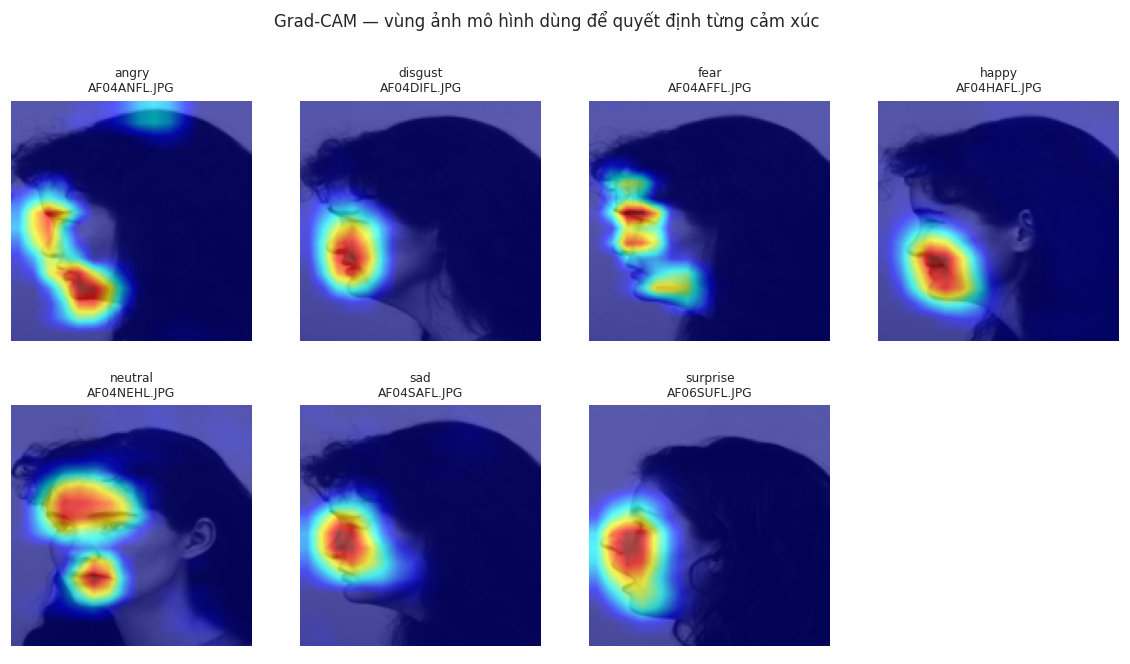

In [28]:
# 9.6 Grad-CAM cho từng lớp cảm xúc (1 ảnh phân loại ĐÚNG mỗi lớp)
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

cam_bo = GradCAM(model=model_cuoi, target_layers=[model_cuoi.features[3][3]])
# features[3][3] = conv thứ hai của khối 4 — tầng conv sâu nhất (256 kênh, trước pool cuối)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for i, lop in enumerate(CLASS_NAMES):
    ax = axes.flat[i]
    idx_dung = np.where((y_kt == i) & (y_doan == i))[0]
    idx = int(idx_dung[0]) if len(idx_dung) else int(np.where(y_kt == i)[0][0])
    duong_dan_anh = ds_kt.samples[idx][0]
    anh_goc = np.asarray(Image.open(duong_dan_anh).convert("L").resize((IMG_SIZE, IMG_SIZE)),
                         dtype=np.float32) / 255.0
    x_cam = EVAL_TF(Image.open(duong_dan_anh)).unsqueeze(0).to(DEVICE)
    cam_map = cam_bo(input_tensor=x_cam, targets=[ClassifierOutputTarget(i)])[0]
    anh_cam = show_cam_on_image(np.stack([anh_goc] * 3, axis=-1), cam_map, use_rgb=True)
    ax.imshow(anh_cam)
    ax.set_title(f"{lop}\n{Path(duong_dan_anh).name}", fontsize=8)
    ax.axis("off")
axes.flat[7].axis("off")
fig.suptitle("Grad-CAM — vùng ảnh mô hình dùng để quyết định từng cảm xúc", y=0.995)
luu_anh(fig, "nb_test_gradcam.png")
plt.show()

Top 6 cặp nhầm lẫn nhiều nhất:
      fear → surprise: 18 ảnh
  surprise → fear    : 17 ảnh
       sad → disgust : 13 ảnh
     angry → fear    : 13 ảnh
   neutral → sad     : 12 ảnh
     angry → disgust : 12 ảnh


Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_test_top_confusions.png


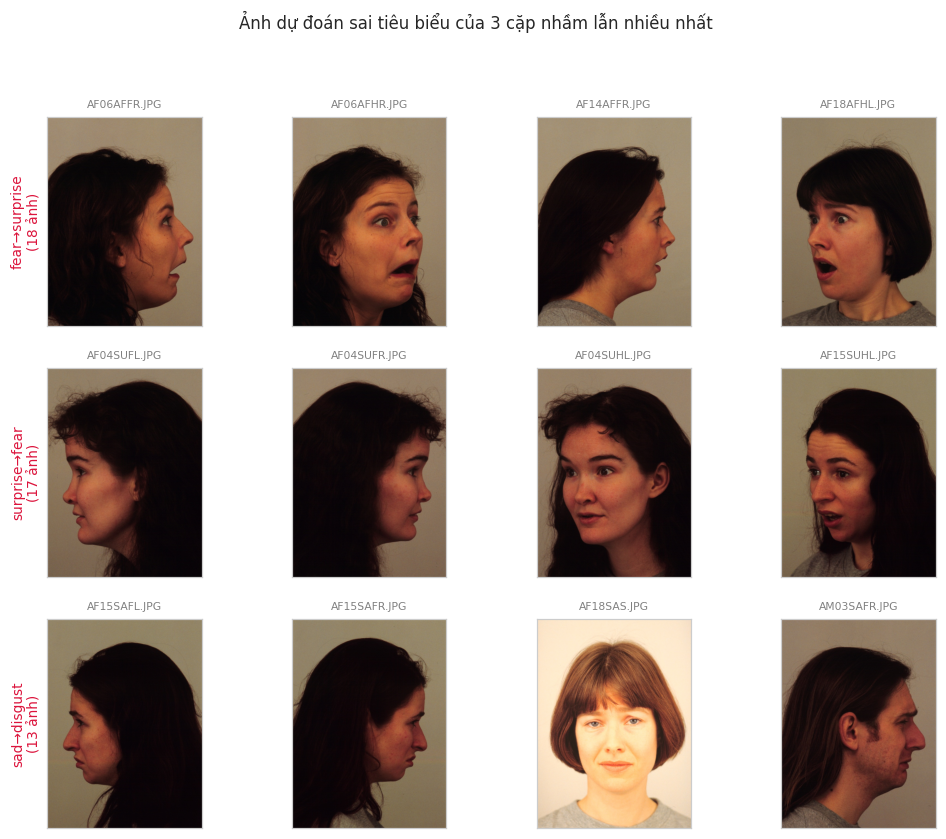

In [29]:
# 9.7 Các cặp nhầm lẫn nhiều nhất + ảnh dự đoán sai tiêu biểu
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True
cm_lech = cm_kt.copy().astype(float)
np.fill_diagonal(cm_lech, 0)
cac_cap = sorted(
    ((int(cm_kt[i, j]), CLASS_NAMES[i], CLASS_NAMES[j], i, j)
     for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j),
    reverse=True,
)
print("Top 6 cặp nhầm lẫn nhiều nhất:")
for n, that, doan, _, _ in cac_cap[:6]:
    print(f"  {that:>8} → {doan:<8}: {n} ảnh")

top_3 = cac_cap[:3]
fig, axes = plt.subplots(3, 4, figsize=(11, 8.4))
for hang_i, (n, that, doan, i_true, j_doan) in enumerate(top_3):
    idx_sai = np.where((y_kt == i_true) & (y_doan == j_doan))[0][:4]
    for k in range(4):
        ax = axes[hang_i, k]
        if k < len(idx_sai):
            duong_dan_anh = ds_kt.samples[int(idx_sai[k])][0]
            ax.imshow(Image.open(duong_dan_anh), cmap="gray")
            ax.set_title(Path(duong_dan_anh).name, fontsize=7, color="gray")
        ax.set_xticks([]); ax.set_yticks([])
        if k == 0:
            ax.set_ylabel(f"{that}→{doan}\n({n} ảnh)", fontsize=9, color="crimson")
fig.suptitle("Ảnh dự đoán sai tiêu biểu của 3 cặp nhầm lẫn nhiều nhất", y=0.995)
luu_anh(fig, "nb_test_top_confusions.png")
plt.show()

In [30]:
# 9.8 Ghi reports/test_metrics.json + đối chiếu khoảng kỳ vọng từ tài liệu
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True
ket_qua_cuoi = {
    "accuracy": float(accuracy_kt),
    "macro_f1": float(f1_macro),
    "weighted_f1": float(f1_wei),
    "per_class_recall": {c: float(recall_theo_lop[c]) for c in CLASS_NAMES},
    "recall_spread": float(recall_spread),
    "confusion_matrix": cm_kt.tolist(),
    "device": str(DEVICE) + (f" ({TEN_GPU})" if TEN_GPU else ""),
    "epochs": int(EPOCHS_CHOT),
    "model_chosen": MO_HINH_CHOT,
    "best_config": {k: (v if isinstance(v, str) else float(v)) for k, v in BEST_CFG.items()},
}
with open(REPORTS_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(ket_qua_cuoi, f, ensure_ascii=False, indent=2)
print("Đã ghi:", REPORTS_DIR / "test_metrics.json")

# Đối chiếu kỳ vọng subject-independent ~65–80% accuracy / 62–77% macro-F1 (Cha 2026; Akhand 2021)
DUOI_KY_VONG, TREN_KY_VONG = 0.65, 0.80
if accuracy_kt > 0.90:
    phan_dinh = "CAO BẤT THƯỜNG so với protocol subject-independent — kiểm tra lại rò rỉ dữ liệu!"
elif accuracy_kt >= TREN_KY_VONG:
    phan_dinh = "TRÊN khoảng kỳ vọng 65–80% — học rất tốt; rà lại thủ tục để chắc chắn không rò rỉ."
elif accuracy_kt >= DUOI_KY_VONG:
    phan_dinh = "TRONG khoảng kỳ vọng 65–80% của protocol subject-independent. ✓"
else:
    phan_dinh = "DƯỚI khoảng kỳ vọng — cân nhắc tăng epoch/điều chỉnh augmentation."
print(f"\nAccuracy tập kiểm tra = {accuracy_kt:.2%} | macro-F1 = {f1_macro:.2%} → {phan_dinh}")

Đã ghi: /mnt/f/Hoc-May/reports/test_metrics.json

Accuracy tập kiểm tra = 82.76% | macro-F1 = 82.75% → TRÊN khoảng kỳ vọng 65–80% — học rất tốt; rà lại thủ tục để chắc chắn không rò rỉ.


## 10) Phân tích sâu từng tầng SAU khi huấn luyện

Lặp lại **cùng quy trình** mục 6 (feature map + histogram activation + filter conv đầu) cho **cùng ảnh mẫu** nhưng với `model_cuoi` đã huấn luyện, rồi đối chiếu trước/sau: filter conv đầu chuyển từ noise → bộ dò cạnh/độ sáng có hướng; activation sâu trở nên **thưa và chọn lọc hơn** (một số kênh chỉ bật với dạng ảnh cụ thể) — dấu hiệu mạng đã học đặc trưng biểu cảm thay vì phản ứng đều với mọi input.

Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_post_feature_maps.png


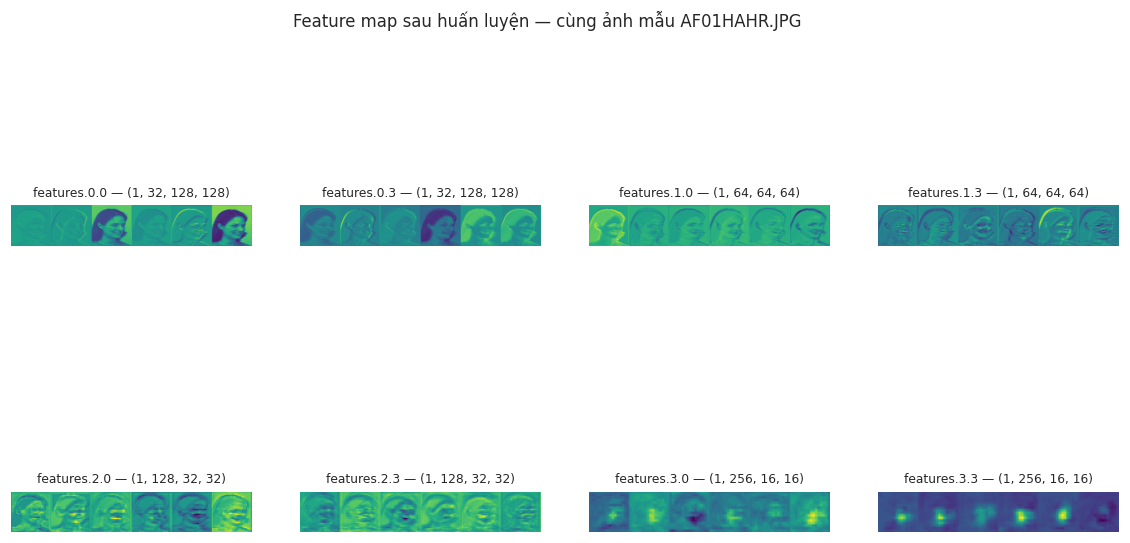

Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_post_activation_hists.png


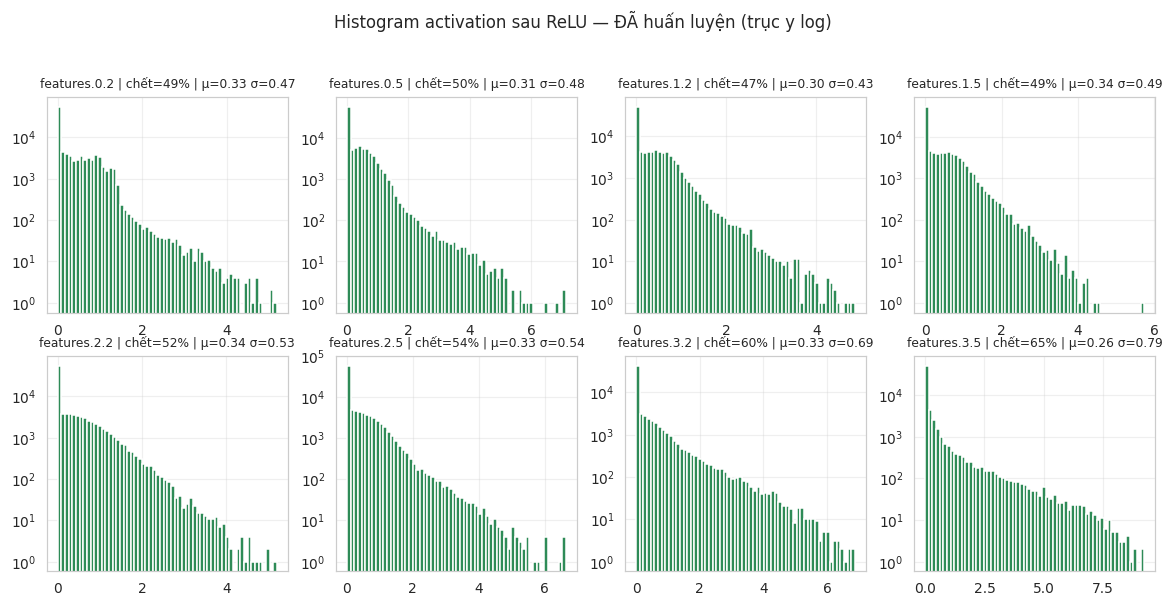

Ảnh mẫu AF01HAHR.JPG (lớp thật happy) → dự đoán sau huấn luyện: happy

So sánh thống kê activation trước → sau huấn luyện:
              dead_truoc  dead_sau  mean_truoc  mean_sau  std_truoc  std_sau
features.0.2       0.500     0.487       0.391     0.326      0.683    0.467
features.0.5       0.555     0.504       0.329     0.311      0.619    0.477
features.1.2       0.496     0.466       0.398     0.301      0.658    0.426
features.1.5       0.402     0.486       0.511     0.340      0.711    0.488
features.2.2       0.493     0.520       0.544     0.336      0.824    0.526
features.2.5       0.488     0.535       0.513     0.328      0.808    0.543
features.3.2       0.512     0.602       0.548     0.326      0.873    0.688
features.3.5       0.525     0.651       0.511     0.259      0.805    0.786


In [31]:
# 10.1 Feature map + histogram của CÙNG ảnh mẫu qua mô hình ĐÃ huấn luyện
assert "TEST_UNLOCKED" in globals() and TEST_UNLOCKED is True
if "x_mau" not in globals() or "SAMPLE_PATH" not in globals():
    raise RuntimeError("Chạy lại mục 6 trước để có x_mau/SAMPLE_PATH dùng chung cho so sánh.")
if "thong_ke_truoc" not in globals():
    with open(FIG_DIR / "nb_pre_layer_stats.json", encoding="utf-8") as f:
        thong_ke_truoc = json.load(f)

du_lieu_sau, hooks_sau = bat_activation(model_cuoi)
model_cuoi.eval()
with torch.no_grad():
    logits_sau = model_cuoi(x_mau.to(DEVICE))
for h in hooks_sau:
    h.remove()

fig, axes = plt.subplots(2, 4, figsize=(13, 6.2))
for k, (ten, act) in enumerate(du_lieu_sau["conv"].items()):
    ax = axes.flat[k]
    dai = np.concatenate([act[0, i].numpy() for i in range(6)], axis=1)
    dai = (dai - dai.min()) / (dai.max() - dai.min() + 1e-8)
    ax.imshow(dai, cmap="viridis")
    ax.set_title(f"{ten} — {tuple(act.shape)}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"Feature map sau huấn luyện — cùng ảnh mẫu {SAMPLE_PATH.name}", y=1.02)
luu_anh(fig, "nb_post_feature_maps.png")
plt.show()

rng_hist = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
thong_ke_sau = {}
for k, (ten, act) in enumerate(du_lieu_sau["relu"].items()):
    a = act.numpy().ravel()
    mau = rng_hist.choice(a, size=min(len(a), 100_000), replace=False)
    axes.flat[k].hist(mau, bins=60, color="seagreen")
    axes.flat[k].set_title(f"{ten} | chết={(a == 0).mean():.0%} | μ={a.mean():.2f} σ={a.std():.2f}",
                           fontsize=8)
    axes.flat[k].set_yscale("log")
    thong_ke_sau[ten] = {"dead_frac": float((a == 0).mean()), "mean": float(a.mean()),
                         "std": float(a.std()), "max": float(a.max())}
fig.suptitle("Histogram activation sau ReLU — ĐÃ huấn luyện (trục y log)", y=1.02)
luu_anh(fig, "nb_post_activation_hists.png")
plt.show()

du_doan_mau = CLASS_NAMES[int(logits_sau.argmax(1).item())]
print(f"Ảnh mẫu {SAMPLE_PATH.name} (lớp thật happy) → dự đoán sau huấn luyện: {du_doan_mau}")

# Bảng so sánh trước/sau từng tầng
bang_ss = pd.DataFrame({
    "dead_truoc": {t: s["dead_frac"] for t, s in thong_ke_truoc.items()},
    "dead_sau": {t: s["dead_frac"] for t, s in thong_ke_sau.items()},
    "mean_truoc": {t: s["mean"] for t, s in thong_ke_truoc.items()},
    "mean_sau": {t: s["mean"] for t, s in thong_ke_sau.items()},
    "std_truoc": {t: s["std"] for t, s in thong_ke_truoc.items()},
    "std_sau": {t: s["std"] for t, s in thong_ke_sau.items()},
})
print("\nSo sánh thống kê activation trước → sau huấn luyện:")
print(bang_ss.round(3))

Đã lưu biểu đồ: /mnt/f/Hoc-May/reports/figures/nb_post_conv1_filters.png


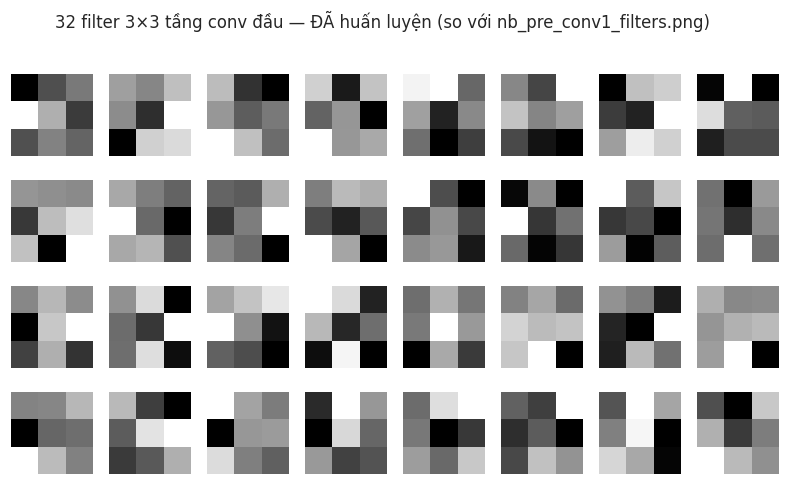

In [32]:
# 10.2 Filter 3×3 tầng conv đầu SAU huấn luyện — so với mục 6.4
w_conv1_sau = model_cuoi.features[0][0].weight.detach().cpu()
fig, axes = plt.subplots(4, 8, figsize=(9, 4.8))
for i in range(w_conv1_sau.shape[0]):
    f = w_conv1_sau[i, 0].numpy()
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)
    axes.flat[i].imshow(f, cmap="gray")
    axes.flat[i].axis("off")
fig.suptitle("32 filter 3×3 tầng conv đầu — ĐÃ huấn luyện (so với nb_pre_conv1_filters.png)", y=0.995)
luu_anh(fig, "nb_post_conv1_filters.png")
plt.show()

**Ghi chú diễn giải (đối chiếu với 2 biểu đồ vừa sinh):**
- **Filter conv đầu (10.2 vs 6.4):** trước huấn luyện các filter là noise cân bằng; sau huấn luyện xuất hiện các filter có cấu trúc hướng (đọc bảng giá trị trọng số: các bộ dò cạnh ngang/dọc và dò vùng sáng/tối) — tầng 1 chuyển thành bộ trích xuất gradient ảnh khuôn mặt.
- **Feature map (10.1 vs 6.2):** trước huấn luyện mọi tầng phản ứng tương tự nhau; sau huấn luyện các tầng sâu (khối 3–4) chỉ còn một số kênh bật mạnh — mạng trở nên **chọn lọc**: kênh phản ứng với mắt/miệng/nét căng của biểu cảm, kênh khác im lặng với ảnh này.
- **Histogram (10.1 vs 6.3):** trước huấn luyện mọi tầng có phân bố gần như nhau (~50% zero sau ReLU); sau huấn luyện các tầng sâu thường **thưa hơn** (tỉ lệ zero tăng) nhưng vẫn còn kênh hoạt động mạnh — mạng dùng ít neuron hơn để mã hóa 1 ảnh cụ thể, tức đặc trưng đã chuyên biệt hóa. Nếu một tầng nào đó **toàn 0** sau huấn luyện thì đó là tầng chết cần xem lại kiến trúc/learning rate.

## 11) Nhận xét — kết luận

### Đối chiếu kỳ vọng
- Cell 9.8 đã tự in phần định của lần chạy (so với khoảng **65–80% accuracy / 62–77% macro-F1** của protocol subject-independent từ Cha et al. 2026 và Akhand et al. 2021 — các con số này là **trích dẫn tài liệu**, kết quả thật nằm trong `reports/test_metrics.json` do cell 9.8 sinh).
- Pattern per-class kỳ vọng theo Calvo & Lundqvist (2008): **happy** cao nhất, nhóm **fear/disgust/anger** thấp hơn — đối chiếu biểu đồ per-class recall (9.3) và các cặp nhầm lẫn (9.7); các cặp fear↔surprise, angry↔disgust thường dẫn đầu vì chia cơ mặt tương tự (Zebrowitz-type confusions).
- Nhớ ngữ cảnh so sánh: Akhand 2021 dùng **split ngẫu nhiên theo ảnh** (78–88%); protocol này **subject-disjoint** khó hơn hẳn — không so số tuyệt đối qua 2 protocol.
- **Mốc đỏ: >90% với protocol subject-independent gần như chắc chắn là rò rỉ** (cell 9.8 tự cảnh báo).

### Hạn chế
- 70 subject KDEF đều người da trắng trẻ, ánh sáng studio đồng nhất → khó khái quát ra ảnh ngoài tự nhiên (Shin 2016: cross-database chỉ ~50%).
- Test lệch gender 64% nữ / 36% nam (14 subject) — accuracy theo gender (9.5) có sai số chuẩn lớn.
- 1 ảnh kích thước lệch chuẩn (633×970) bị resize về 128×128 như mọi ảnh.
- CNN tự thiết kế ~1,24M tham số — cố ý theo công thức tài liệu; transfer learning (Akhand 2021 đạt 96,5% nhưng split ngẫu nhiên) là hướng mở.

### Hướng phát triển
- Thử tiền xử lý CLAHE/histogram equalization (Shin 2016 gợi ý là baseline mạnh) — một biến thể transform trong grid mục 8.
- Fusion đặc trưng handcrafted + CNN (Cha 2026: ~80% acc / macro-F1 0,77–0,79 LOSO).
- Transfer learning từ backbone pretrained trên ảnh khuôn mặt, fine-tune với lr nhỏ.
- Mở rộng dataset khác (CK+, JAFFE) đánh giá cross-database.

### Tài liệu tham khảo
1. Lundqvist, D., Flykt, A., & Öhman, A. (1998). *The Karolinska Directed Emotional Faces — KDEF*. Karolinska Institutet, kdef.se — 4.900 ảnh, 70 người, 7 biểu cảm × 5 góc chụp.
2. Calvo, M. G., & Lundqvist, D. (2008). Facial expressions of emotion (KDEF): Identification at different viewing distances. *Behavior Research Methods*, 40(1) — happy ~98% cao nhất; fear/disgust/anger thấp hơn.
3. Cha et al. (2026). LOSO subject-independent trên KDEF (840 ảnh chính diện, 6 lớp): CNN thuần 60–78% acc; fusion ~80% acc / macro-F1 0,77–0,79; LeNet-5 thắng ResNet-152 (59,9%). PMC13416614.
4. Akhand, M. A. H. et al. (2021). CNN 2 tầng theo input 48/64/128/224 trên KDEF: 61,6/69,4/80,8/73,5% → 128×128 tối ưu; VGG-16 từ đầu 23,4%, transfer 96,5%; augmentation nhẹ (xoay ±10°, scale ×1,1, flip) tốt nhất. *Electronics*, 10(9).
5. Shin, M., Kim, D., & Kwon, D.-S. (2016). CNN + dropout + histogram equalization là baseline mạnh; KDEF cross-database chỉ 50,66%. arXiv:1611.04251.
6. Ruiz-Garcia et al. (2017). SCAE+CNN 92,52% trên 980 ảnh KDEF chính diện, split ngẫu nhiên 70/30 (trích theo bảng của Akhand 2021).
7. Szegedy, C. et al. (2016). Rethinking the Inception Architecture — label smoothing (1−ε)·one-hot + ε/K. CVPR 2016, arXiv:1512.00567.
8. Loshchilov, I., & Hutter, F. (2019). Decoupled Weight Decay Regularization (AdamW). ICLR, OpenReview Bkg6RiCqY7.
9. Zhong, Z. et al. (2020). Random Erasing — xóa vùng chữ nhật ngẫu nhiên khi huấn luyện, giảm overfit. AAAI 2020.
10. Rosenblatt et al. (2024) & Apicella et al. (2025). Subject/overlap leakage thổi phồng hiệu năng; phải chia split theo ID người và chọn mô hình theo macro-F1 trên val.

---
*Notebook này được sinh bởi `nbformat`, kiểm tra tự động bởi `scripts/verify_notebook.py` (kỷ luật khóa tập kiểm tra + tính đầy đủ của `reports/test_metrics.json`).*